# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Ananda Putri Cahyani
- **Email:** anandda92@gmail.com
- **ID Dicoding:** nandaputri

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam.

* **Specific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau metrik yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Konteks bisnis dan definisi yang dipakai.** Dataset berisi transaksi marketplace e-commerce Brasil (Olist) dari September 2016 sampai Oktober 2018. Volume pesanan pada 2016 dan pada September-Oktober 2018 sangat kecil (kurang dari 400 pesanan per bulan), sehingga **periode analisis dibatasi pada Januari 2017 - Agustus 2018** (20 bulan penuh). Selain itu:

- Hanya pesanan berstatus **delivered** yang dihitung sebagai penjualan.
- **Revenue** = jumlah `price` item (tanpa ongkos kirim / `freight_value`), dalam Real Brasil (R\$).
- Pesanan dianggap **terlambat** bila tanggal tiba di pelanggan lebih lambat dari tanggal estimasi (dibandingkan pada level tanggal).

**Pertanyaan bisnis (SMART):**

- **Pertanyaan 1:** Bagaimana tren jumlah pesanan dan revenue bulanan dari pesanan *delivered* pada periode Januari 2017 - Agustus 2018, dan pada bulan apa terjadi lonjakan serta penurunan terbesar secara Month-over-Month (MoM), sehingga tim marketing dapat menyiapkan kampanye dan stok pada periode puncak?
- **Pertanyaan 2:** Kategori produk apa saja yang menyumbang revenue terbesar dan terkecil (10 teratas dan 10 terbawah) pada periode Januari 2017 - Agustus 2018, dan berapa persen total revenue yang disumbang oleh 10 kategori teratas, sehingga tim merchandising dapat menentukan kategori prioritas untuk promosi dan penambahan seller?
- **Pertanyaan 3:** Berapa persentase pesanan *delivered* yang tiba terlambat dari estimasi di setiap state pada periode Januari 2017 - Agustus 2018, dan berapa selisih rata-rata review score antara pesanan tepat waktu dan terlambat (per rentang hari keterlambatan), sehingga tim logistik dapat menentukan state dan batas keterlambatan yang harus diprioritaskan?
- **Pertanyaan 4:** Bagaimana segmentasi pelanggan berdasarkan RFM (Recency, Frequency, Monetary) per 30 Agustus 2018, berapa jumlah pelanggan dan kontribusi revenue tiap segmen, serta berapa persen pelanggan yang melakukan pembelian ulang selama Januari 2017 - Agustus 2018, sehingga tim CRM dapat menentukan segmen yang perlu diprioritaskan untuk kampanye retensi?

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="white")
pd.set_option("display.max_columns", 50)

# Warna konsisten: satu warna sorot untuk pesan utama, abu-abu untuk pembanding
HIGHLIGHT = "#72BCD4"
GREY = "#D3D3D3"

## Data Wrangling

### Gathering Data

In [2]:
# Lokasi data: lokal (folder data/) atau Google Colab (Google Drive)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/data'
except ImportError:
    DATA_DIR = 'data'

print("Folder data:", DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

Mounted at /content/drive
Folder data: /content/drive/MyDrive/data
['customers_dataset.csv', 'geolocation_dataset.csv', 'order_items_dataset.csv', 'order_payments_dataset.csv', 'order_reviews_dataset.csv', 'orders_dataset.csv', 'product_category_name_translation.csv', 'products_dataset.csv', 'sellers_dataset.csv']


#### Load df customers

In [3]:
customers = pd.read_csv(f'{DATA_DIR}/customers_dataset.csv')
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


#### Load df orders

In [4]:
orders = pd.read_csv(f'{DATA_DIR}/orders_dataset.csv')
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load df order items

In [5]:
order_items = pd.read_csv(f'{DATA_DIR}/order_items_dataset.csv')
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


#### Load df order payments

In [6]:
payments = pd.read_csv(f'{DATA_DIR}/order_payments_dataset.csv')
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


#### Load df order reviews

In [7]:
reviews = pd.read_csv(f'{DATA_DIR}/order_reviews_dataset.csv')
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


#### Load df geolocation

In [8]:
geolocation = pd.read_csv(f'{DATA_DIR}/geolocation_dataset.csv')
geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


#### Load df order categories

In [9]:
categories = pd.read_csv(f'{DATA_DIR}/product_category_name_translation.csv')
categories.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


#### Load df products

In [10]:
products = pd.read_csv(f'{DATA_DIR}/products_dataset.csv')
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


#### Load df sellers

In [11]:
sellers = pd.read_csv(f'{DATA_DIR}/sellers_dataset.csv')
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [12]:
tables = {
    "customers": customers, "orders": orders, "order_items": order_items,
    "products": products, "categories": categories,
    "payments": payments, "reviews": reviews, "sellers": sellers,
    "geolocation": geolocation,
}
pd.DataFrame({name: {"jumlah_baris": df.shape[0], "jumlah_kolom": df.shape[1]}
              for name, df in tables.items()}).T

,jumlah_baris,jumlah_kolom
customers,99441,5
orders,99441,8
order_items,112650,7
products,32951,9
categories,71,2
payments,103886,5
reviews,99224,7
sellers,3095,4
geolocation,1000163,5


**Insight:**
- Terdapat sembilan tabel dengan relasi antartabel sebagai berikut: `orders` - `customers` (via `customer_id`), `orders` - `order_items` / `payments` / `reviews` (via `order_id`), `order_items` - `products` (via `product_id`) dan `sellers` (via `seller_id`), serta `customers`/`sellers` - `geolocation` (via kode pos).
- Tabel terbesar adalah `geolocation` (1.000.163 baris), diikuti `order_items` (112.650 baris). Tabel `orders` dan `customers` masing-masing 99.441 baris.
- Rentang tanggal pesanan sangat panjang (2016-2018), sehingga periode analisis perlu ditentukan pada tahap berikutnya.

### Assessing Data

#### Identifying table: customers problem

In [13]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [14]:
print("Jumlah missing value:", customers.isna().sum().sum())
print("Jumlah duplikasi:", customers.duplicated().sum())

Jumlah missing value: 0
Jumlah duplikasi: 0


In [15]:
print("customer_id unik:", customers["customer_id"].nunique())
print("customer_unique_id unik:", customers["customer_unique_id"].nunique())
print("Jumlah state:", customers["customer_state"].nunique())

customer_id unik: 99441
customer_unique_id unik: 96096
Jumlah state: 27


In [16]:
customers.describe()

,customer_zip_code_prefix
count,99441.000000
mean,35137.474583
std,29797.938996
min,1003.000000
25%,11347.000000
50%,24416.000000
75%,58900.000000
max,99990.000000


#### Identifying table: orders problem

In [17]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [18]:
orders.describe()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [19]:
print("Jumlah missing value:", orders.isna().sum().sum())
print("Jumlah duplikasi:", orders.duplicated().sum())
orders.isna().sum()

Jumlah missing value: 4908
Jumlah duplikasi: 0


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [20]:
# Konsistensi status dengan tanggal tiba
delivered_no_date = ((orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()).sum()
not_delivered_with_date = ((orders["order_status"] != "delivered") & orders["order_delivered_customer_date"].notna()).sum()
print("Status delivered tetapi tanggal tiba kosong:", delivered_no_date)
print("Status bukan delivered tetapi tanggal tiba ada:", not_delivered_with_date)

# Missing value pada tanggal tiba berdasarkan status pesanan
print()
print("Missing tanggal tiba per status pesanan:")
print(orders[orders["order_delivered_customer_date"].isna()]["order_status"].value_counts())

Status delivered tetapi tanggal tiba kosong: 8
Status bukan delivered tetapi tanggal tiba ada: 6

Missing tanggal tiba per status pesanan:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [21]:
# Kewajaran urutan waktu (dikonversi sementara ke datetime hanya untuk pengecekan)
ts = orders.copy()
for col in ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]:
    ts[col] = pd.to_datetime(ts[col])

print("Tanggal serah ke kurir lebih awal dari tanggal pembelian:", (ts["order_delivered_carrier_date"] < ts["order_purchase_timestamp"]).sum())
print("Tanggal tiba lebih awal dari tanggal serah ke kurir:", (ts["order_delivered_customer_date"] < ts["order_delivered_carrier_date"]).sum())
print("Tanggal tiba lebih awal dari tanggal pembelian:", (ts["order_delivered_customer_date"] < ts["order_purchase_timestamp"]).sum())

# Sebaran pesanan per bulan -> menentukan periode analisis yang layak
ts.groupby(ts["order_purchase_timestamp"].dt.to_period("M")).size().rename("jumlah_pesanan").to_frame().T

Tanggal serah ke kurir lebih awal dari tanggal pembelian: 166
Tanggal tiba lebih awal dari tanggal serah ke kurir: 23
Tanggal tiba lebih awal dari tanggal pembelian: 0


order_purchase_timestamp,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10
jumlah_pesanan,4,324,1,800,1780,2682,2404,3700,3245,4026,4331,4285,4631,7544,5673,7269,6728,7211,6939,6873,6167,6292,6512,16,4


#### Identifying table: order_items problem

In [22]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [23]:
print("Jumlah missing value:", order_items.isna().sum().sum())
print("Jumlah duplikasi:", order_items.duplicated().sum())

Jumlah missing value: 0
Jumlah duplikasi: 0


In [24]:
order_items.describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [25]:
# Outlier harga (aturan IQR)
q1, q3 = order_items["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
n_out = (order_items["price"] > upper).sum()
print(f"Batas atas outlier harga (IQR): R$ {upper:,.2f}")
print(f"Jumlah item di atas batas: {n_out} ({n_out / len(order_items):.1%})")
print("Harga maksimum: R$", order_items["price"].max())
print("Item dengan ongkir 0:", (order_items["freight_value"] == 0).sum())

Batas atas outlier harga (IQR): R$ 277.40
Jumlah item di atas batas: 8427 (7.5%)
Harga maksimum: R$ 6735.0
Item dengan ongkir 0: 383


#### Identifying table: products problem

In [26]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [27]:
print("Jumlah missing value:", products.isna().sum().sum())
print("Jumlah duplikasi:", products.duplicated().sum())
products.isna().sum()

Jumlah missing value: 2448
Jumlah duplikasi: 0


,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [28]:
products.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [29]:
print("Produk dengan berat 0 gram (tidak valid):", (products["product_weight_g"] == 0).sum())
missing_translation = set(products["product_category_name"].dropna()) - set(categories["product_category_name"])
print("Kategori produk yang tidak punya terjemahan:", missing_translation)

Produk dengan berat 0 gram (tidak valid): 4
Kategori produk yang tidak punya terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


In [30]:
print(products["product_category_name"].unique())

['perfumaria' 'artes' 'esporte_lazer' 'bebes' 'utilidades_domesticas'
 'instrumentos_musicais' 'cool_stuff' 'moveis_decoracao'
 'eletrodomesticos' 'brinquedos' 'cama_mesa_banho'
 'construcao_ferramentas_seguranca' 'informatica_acessorios'
 'beleza_saude' 'malas_acessorios' 'ferramentas_jardim'
 'moveis_escritorio' 'automotivo' 'eletronicos' 'fashion_calcados'
 'telefonia' 'papelaria' 'fashion_bolsas_e_acessorios' 'pcs'
 'casa_construcao' 'relogios_presentes'
 'construcao_ferramentas_construcao' 'pet_shop' 'eletroportateis'
 'agro_industria_e_comercio' nan 'moveis_sala' 'sinalizacao_e_seguranca'
 'climatizacao' 'consoles_games' 'livros_interesse_geral'
 'construcao_ferramentas_ferramentas' 'fashion_underwear_e_moda_praia'
 'fashion_roupa_masculina'
 'moveis_cozinha_area_de_servico_jantar_e_jardim'
 'industria_comercio_e_negocios' 'telefonia_fixa'
 'construcao_ferramentas_iluminacao' 'livros_tecnicos'
 'eletrodomesticos_2' 'artigos_de_festas' 'bebidas' 'market_place'
 'la_cuisine' 'const

In [31]:
print(categories["product_category_name_english"].unique())

['health_beauty' 'computers_accessories' 'auto' 'bed_bath_table'
 'furniture_decor' 'sports_leisure' 'perfumery' 'housewares' 'telephony'
 'watches_gifts' 'food_drink' 'baby' 'stationery' 'tablets_printing_image'
 'toys' 'fixed_telephony' 'garden_tools' 'fashion_bags_accessories'
 'small_appliances' 'consoles_games' 'audio' 'fashion_shoes' 'cool_stuff'
 'luggage_accessories' 'air_conditioning'
 'construction_tools_construction'
 'kitchen_dining_laundry_garden_furniture' 'costruction_tools_garden'
 'fashion_male_clothing' 'pet_shop' 'office_furniture' 'market_place'
 'electronics' 'home_appliances' 'party_supplies' 'home_confort'
 'costruction_tools_tools' 'agro_industry_and_commerce'
 'furniture_mattress_and_upholstery' 'books_technical' 'home_construction'
 'musical_instruments' 'furniture_living_room' 'construction_tools_lights'
 'industry_commerce_and_business' 'food' 'art' 'furniture_bedroom'
 'books_general_interest' 'construction_tools_safety'
 'fashion_underwear_beach' 'fashion_

#### Identifying table: product_category_name_translation problem

In [32]:
categories.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [33]:
print("Jumlah missing value:", categories.isna().sum().sum())
print("Jumlah duplikasi:", categories.duplicated().sum())
# Cek salah ketik pada nama kategori Inggris (terlihat pada daftar di atas)
categories[categories["product_category_name_english"].str.contains("costruction|fashio_|confort")]

Jumlah missing value: 0
Jumlah duplikasi: 0


,product_category_name,product_category_name_english
27,construcao_ferramentas_jardim,costruction_tools_garden
35,casa_conforto,home_confort
36,construcao_ferramentas_ferramentas,costruction_tools_tools
55,fashion_roupa_feminina,fashio_female_clothing


#### Identifying table: payments problem

In [34]:
payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [35]:
print("Jumlah missing value:", payments.isna().sum().sum())
print("Jumlah duplikasi:", payments.duplicated().sum())

Jumlah missing value: 0
Jumlah duplikasi: 0


In [36]:
payments["payment_type"].value_counts()

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


In [37]:
payments.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [38]:
print("Baris dengan payment_type 'not_defined':")
print(payments[payments["payment_type"] == "not_defined"])
print("Baris dengan payment_value = 0:", (payments["payment_value"] == 0).sum())
print("Baris dengan payment_installments = 0:", (payments["payment_installments"] == 0).sum())

Baris dengan payment_type 'not_defined':
                               order_id  payment_sequential payment_type  \
51280  4637ca194b6387e2d538dc89b124b0ee                   1  not_defined   
57411  00b1cb0320190ca0daa2c88b35206009                   1  not_defined   
94427  c8c528189310eaa44a745b8d9d26908b                   1  not_defined   

       payment_installments  payment_value  
51280                     1            0.0  
57411                     1            0.0  
94427                     1            0.0  
Baris dengan payment_value = 0: 9
Baris dengan payment_installments = 0: 2


#### Identifying table: reviews problem

In [39]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [40]:
print("Jumlah missing value:", reviews.isna().sum().sum())
print("Jumlah duplikasi:", reviews.duplicated().sum())
reviews.isna().sum()

Jumlah missing value: 145903
Jumlah duplikasi: 0


,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [41]:
print("review_id yang berulang:", reviews["review_id"].duplicated().sum())

reviews[reviews["review_id"].duplicated(keep=False)].sort_values("review_id").head(10)

review_id yang berulang: 814


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [42]:
# Satu pesanan bisa memiliki lebih dari satu review
print("Jumlah review per pesanan:")
print(reviews.groupby("order_id").size().value_counts())

Jumlah review per pesanan:
1    98126
2      543
3        4
Name: count, dtype: int64


#### Identifying table: sellers problem

In [43]:
sellers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [44]:
print("Jumlah missing value:", sellers.isna().sum().sum())
print("Jumlah duplikasi:", sellers.duplicated().sum())

Jumlah missing value: 0
Jumlah duplikasi: 0


In [45]:
sellers.describe()

,seller_zip_code_prefix
count,3095.000000
mean,32291.059451
std,32713.453830
min,1001.000000
25%,7093.500000
50%,14940.000000
75%,64552.500000
max,99730.000000


#### Identifying table: geolocation problem

In [46]:
geolocation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [47]:
print("Jumlah missing value:", geolocation.isna().sum().sum())
print("Jumlah duplikasi:", geolocation.duplicated().sum())

Jumlah missing value: 0
Jumlah duplikasi: 261831


In [48]:
geolocation.describe()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,1.000163e+06,1.000163e+06,1.000163e+06
mean,3.657417e+04,-2.117615e+01,-4.639054e+01
std,3.054934e+04,5.715866e+00,4.269748e+00
min,1.001000e+03,-3.660537e+01,-1.014668e+02
25%,1.107500e+04,-2.360355e+01,-4.857317e+01
50%,2.653000e+04,-2.291938e+01,-4.663788e+01
75%,6.350400e+04,-1.997962e+01,-4.376771e+01
max,9.999000e+04,4.506593e+01,1.211054e+02


In [49]:
# Kode pos unik
print("Kode pos unik:", geolocation["geolocation_zip_code_prefix"].nunique())

# Koordinat di luar wilayah Brasil (lat -33.75 s.d. 5.30, lng -73.99 s.d. -34.79)
outside = ~(geolocation["geolocation_lat"].between(-33.75, 5.30) & geolocation["geolocation_lng"].between(-73.99, -34.79))
print("Baris dengan koordinat di luar Brasil:", outside.sum())

Kode pos unik: 19015
Baris dengan koordinat di luar Brasil: 42


**Steps to Take:**
1. Pada dataset `orders`, `order_items`, dan `reviews`, ditemukan ketidaksesuaian tipe data pada kolom tanggal yang masih bertipe object. Oleh karena itu, tipe data kolom tanggal perlu diubah menjadi datetime.
2. Pada dataset `orders`, ditemukan sebanyak 4.908 missing value. Selain itu, terdapat 8 pesanan berstatus delivered tanpa tanggal tiba, sedangkan 6 pesanan berstatus non-delivered justru memiliki tanggal kedatangan. Missing pada tanggal approve/kurir/tiba umumnya wajar karena pesanan belum sampai di tahap tersebut, jadi tidak diisi (imputasi). Solusi: analisis penjualan hanya memakai pesanan `delivered` yang memiliki tanggal tiba, dan dibatasi pada periode Januari 2017 - Agustus 2018 (bulan lain volumenya terlalu kecil).
3. Pada dataset `products`, ditemukan sebanyak 2.448 missing value (610 kategori kosong), 4 produk berat 0 gram (invalid value), 2 kategori tanpa terjemahan, dan beberapa nama kategori Inggris salah ketik. Solusi: kategori kosong diisi `unknown`, berat 0 diubah menjadi NaN, terjemahan dilengkapi, dan salah ketik diperbaiki.
4. Pada dataset `reviews`, ditemukan sebanyak 145.903 missing value, tetapi hampir seluruhnya adalah kolom judul/komentar yang memang opsional sehingga dibiarkan. Masalah sebenarnya adalah `review_id` berulang dan satu pesanan bisa punya lebih dari satu review (duplicate data). Solusi: ambil review terakhir per pesanan.
5. Pada dataset `payments` terdapat 3 nilai not_defined (nilai pembayaran 0). Solusi: baris tersebut dihapus.
6. Pada dataset `geolocation` terdapat duplikasi sebesar 261.831 baris dan koordinat di luar wilayah Brasil (outlier/inaccurate value). Solusi: hapus duplikat, buang koordinat di luar Brasil, lalu ambil rata-rata koordinat per kode pos.
7. Pada dataset `order_items`, harga memiliki outlier yang tinggi, namun nilainya wajar untuk barang bernilai tinggi (bukan kesalahan input), sehingga dipertahankan. Pada `orders` juga ada urutan waktu yang tidak logis (tanggal serah ke kurir lebih awal dari tanggal beli); kolom tersebut tidak dipakai dalam analisis sehingga tidak diubah.

**Insight:**
- **Tipe data:** seluruh kolom tanggal pada `orders`, `order_items`, dan `reviews` masih bertipe object (teks).
- **Missing value:** `orders` memiliki 4.908 missing value pada tanggal approve/kurir/tiba. Sebagian besar wajar karena pesanan belum/tidak sampai tahap itu (canceled, unavailable, dll). Namun ada 8 pesanan *delivered* tanpa tanggal tiba dan 6 pesanan *canceled* yang justru punya tanggal tiba (**inconsistent value**). `products` punya 610 kategori kosong.
- **Duplicate data:** `geolocation` memiliki 261.831 baris duplikat. `reviews` memiliki 814 `review_id` berulang dan 547 pesanan memiliki lebih dari satu review.
- **Invalid/inaccurate value:** 3 pembayaran bertipe `not_defined` bernilai 0; 4 produk berbobot 0 gram; 42 titik `geolocation` berada di luar Brasil; 166 pesanan punya tanggal serah ke kurir lebih awal dari tanggal beli.
- **Inconsistent value:** 2 kategori produk tidak punya terjemahan dan ada nama kategori yang salah ketik (`costruction_*`, `fashio_*`, `home_confort`).
- **Outlier:** harga item maksimum R\$ 6.735 (jauh di atas batas IQR), tetapi wajar untuk barang bernilai tinggi sehingga dipertahankan.
- **Periode data:** pesanan sangat sedikit pada 2016 dan September-Oktober 2018 (kurang dari 400 per bulan) dibanding 2017-2018 (800 hingga lebih dari 7.000 per bulan), sehingga analisis dibatasi pada Januari 2017 - Agustus 2018.
- `customer_unique_id` (96.096) lebih sedikit daripada `customer_id` (99.441): `customer_id` dibuat per pesanan, jadi pelanggan yang sama dapat muncul beberapa kali. Untuk RFM wajib memakai `customer_unique_id`.

### Cleaning Data

#### Fixing tipe data tanggal

In [50]:
def parse_datetime(series):
    try:
        return pd.to_datetime(series, format="%Y-%m-%d %H:%M:%S")
    except ValueError:
        return pd.to_datetime(series, format="%d-%m-%Y %H:%M")

date_cols_orders = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                    "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols_orders:
    orders[col] = parse_datetime(orders[col])

order_items["shipping_limit_date"] = parse_datetime(order_items["shipping_limit_date"])
for col in ["review_creation_date", "review_answer_timestamp"]:
    reviews[col] = parse_datetime(reviews[col])

orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


#### Fixing orders

Hanya pesanan yang **delivered, memiliki tanggal tiba, dan dibeli pada Januari 2017 - Agustus 2018** yang dipakai. Dengan filter ini 8 pesanan delivered tanpa tanggal tiba dan 6 pesanan canceled yang punya tanggal tiba otomatis tidak terpakai. Dua kolom turunan juga dibuat: `delay_days` (selisih hari tanggal tiba dan tanggal estimasi) dan `is_late`.

In [51]:
PERIOD_START = pd.Timestamp("2017-01-01")
PERIOD_END = pd.Timestamp("2018-08-31 23:59:59")

mask_delivered = (orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].notna()
mask_period = orders["order_purchase_timestamp"].between(PERIOD_START, PERIOD_END)

print("Total pesanan awal                  :", len(orders))
print("Delivered dan ada tanggal tiba      :", mask_delivered.sum())
print("Delivered + periode Jan 2017-Agu 2018:", (mask_delivered & mask_period).sum())

orders_valid = orders[mask_delivered & mask_period].copy()

# Kolom turunan
orders_valid["order_month"] = orders_valid["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
orders_valid["delay_days"] = (orders_valid["order_delivered_customer_date"].dt.normalize()
                              - orders_valid["order_estimated_delivery_date"].dt.normalize()).dt.days
orders_valid["is_late"] = orders_valid["delay_days"] > 0
orders_valid["delivery_days"] = (orders_valid["order_delivered_customer_date"]
                                 - orders_valid["order_purchase_timestamp"]).dt.total_seconds() / 86400

print("Pesanan valid:", len(orders_valid), "| tanggal tiba sebelum tanggal beli:", (orders_valid["delivery_days"] < 0).sum())
orders_valid[["order_id", "order_month", "delay_days", "is_late", "delivery_days"]].head()

Total pesanan awal                  : 99441
Delivered dan ada tanggal tiba      : 96470
Delivered + periode Jan 2017-Agu 2018: 96203
Pesanan valid: 96203 | tanggal tiba sebelum tanggal beli: 0


,order_id,order_month,delay_days,is_late,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-01,-8,False,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-01,-6,False,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-01,-18,False,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-01,-13,False,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-01,-10,False,2.873877


#### Fixing products

Kategori kosong diisi `unknown`, berat 0 gram dianggap tidak valid (NaN), tabel terjemahan dilengkapi untuk 2 kategori yang hilang, dan nama kategori Inggris yang salah ketik diperbaiki. Kolom dimensi/berat yang kosong tidak diimputasi karena tidak dipakai pada pertanyaan bisnis.

In [52]:
products_clean = products.copy()
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("unknown")
products_clean.loc[products_clean["product_weight_g"] == 0, "product_weight_g"] = np.nan

# Lengkapi terjemahan + perbaiki salah ketik
translation = pd.concat([
    categories,
    pd.DataFrame({
        "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos", "unknown"],
        "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers", "unknown"],
    }),
], ignore_index=True)
typo_fix = {
    "fashio_female_clothing": "fashion_female_clothing",
    "costruction_tools_garden": "construction_tools_garden",
    "costruction_tools_tools": "construction_tools_tools",
    "home_confort": "home_comfort",
}
translation["product_category_name_english"] = translation["product_category_name_english"].replace(typo_fix)

products_clean = products_clean.merge(translation, on="product_category_name", how="left")
print("Kategori tanpa terjemahan:", products_clean["product_category_name_english"].isna().sum())
print("Produk berkategori unknown:", (products_clean["product_category_name_english"] == "unknown").sum())
products_clean[["product_id", "product_category_name", "product_category_name_english"]].head()

Kategori tanpa terjemahan: 0
Produk berkategori unknown: 610


,product_id,product_category_name,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares


#### Fixing reviews

Satu pesanan bisa memiliki lebih dari satu review. Agar satu pesanan tidak terhitung ganda saat digabung, diambil **review terakhir** (berdasarkan `review_answer_timestamp`) untuk setiap pesanan. Kolom judul/komentar yang kosong dibiarkan karena memang opsional.

In [53]:
reviews_clean = (reviews.sort_values("review_answer_timestamp")
                        .drop_duplicates(subset="order_id", keep="last")
                        .reset_index(drop=True))

print("Review sebelum :", len(reviews))
print("Review sesudah :", len(reviews_clean), "(1 review per pesanan)")
print("order_id duplikat setelah dibersihkan:", reviews_clean["order_id"].duplicated().sum())

Review sebelum : 99224
Review sesudah : 98673 (1 review per pesanan)
order_id duplikat setelah dibersihkan: 0


#### Fixing payments

Tiga baris `not_defined` memiliki nilai pembayaran 0, sehingga dihapus.

In [54]:
payments_clean = payments[payments["payment_type"] != "not_defined"].copy()
print("Baris dihapus:", len(payments) - len(payments_clean))
payments_clean["payment_type"].value_counts()

Baris dihapus: 3


,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529


#### Fixing geolocation

Duplikat dihapus, koordinat di luar Brasil dibuang, lalu koordinat dirata-ratakan per kode pos sehingga setiap kode pos hanya memiliki satu titik (dipakai untuk analisis geospasial).

In [55]:
geo_clean = geolocation.drop_duplicates().copy()
print("Setelah hapus duplikat:", len(geo_clean))

in_brazil = (geo_clean["geolocation_lat"].between(-33.75, 5.30)
             & geo_clean["geolocation_lng"].between(-73.99, -34.79))
geo_clean = geo_clean[in_brazil]
print("Setelah buang koordinat di luar Brasil:", len(geo_clean))

geo_zip = (geo_clean.groupby("geolocation_zip_code_prefix", as_index=False)
                    .agg(customer_lat=("geolocation_lat", "mean"), customer_lng=("geolocation_lng", "mean")))
print("Kode pos unik dengan koordinat:", len(geo_zip))
geo_zip.head()

Setelah hapus duplikat: 738332
Setelah buang koordinat di luar Brasil: 738299
Kode pos unik dengan koordinat: 19010


,geolocation_zip_code_prefix,customer_lat,customer_lng
0,1001,-23.550227,-46.634039
1,1002,-23.547657,-46.634991
2,1003,-23.549000,-46.635582
3,1004,-23.549829,-46.634792
4,1005,-23.549547,-46.636406


#### Menggabungkan data (all_df)

Tabel digabung pada level **item pesanan** (satu baris = satu item) dengan hanya pesanan valid. Jumlah baris dicek di setiap langkah untuk memastikan tidak ada baris yang menggandakan data.

In [56]:
REGION_MAP = {
    "AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte", "RO": "Norte", "RR": "Norte", "TO": "Norte",
    "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste", "PB": "Nordeste",
    "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste", "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
    "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}

all_df = order_items.merge(orders_valid, on="order_id", how="inner")
n1 = len(all_df)
all_df = all_df.merge(customers, on="customer_id", how="left")
all_df = all_df.merge(products_clean[["product_id", "product_category_name_english"]], on="product_id", how="left")
all_df = all_df.merge(reviews_clean[["order_id", "review_score"]], on="order_id", how="left")
all_df = all_df.merge(geo_zip, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left") \
               .drop(columns="geolocation_zip_code_prefix")
all_df = all_df.rename(columns={"product_category_name_english": "product_category"})
all_df["region"] = all_df["customer_state"].map(REGION_MAP)
all_df["revenue"] = all_df["price"]

assert len(all_df) == n1, "Jumlah baris berubah setelah merge (ada duplikasi kunci)"
print("Jumlah baris item :", len(all_df))
print("Jumlah pesanan    :", all_df["order_id"].nunique())
print("Jumlah pelanggan  :", all_df["customer_unique_id"].nunique())
print("Periode           :", all_df["order_purchase_timestamp"].min().date(), "s.d.", all_df["order_purchase_timestamp"].max().date())
print()
print("Missing value pada all_df (kolom yang terisi sebagian):")
miss = all_df.isna().sum()
print(miss[miss > 0])

Jumlah baris item : 109872
Jumlah pesanan    : 96203
Jumlah pelanggan  : 93096
Periode           : 2017-01-05 s.d. 2018-08-29

Missing value pada all_df (kolom yang terisi sebagian):
order_approved_at                15
order_delivered_carrier_date      1
review_score                    823
customer_lat                    289
customer_lng                    289
dtype: int64


In [57]:
all_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_month,delay_days,is_late,delivery_days,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,product_category,review_score,customer_lat,customer_lng,region,revenue
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,2017-09-01,-9,False,7.614421,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,cool_stuff,5.0,-21.763186,-41.310265,Sudeste,58.90
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,2017-04-01,-3,False,16.216181,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,pet_shop,4.0,-20.222506,-50.898951,Sudeste,239.90
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,2018-01-01,-14,False,7.948437,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,furniture_decor,5.0,-19.869998,-44.593059,Sudeste,199.00
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,2018-08-01,-6,False,6.147269,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,perfumery,4.0,-23.105968,-46.590277,Sudeste,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,2017-02-01,-16,False,25.114352,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,garden_tools,5.0,-23.243402,-46.827614,Sudeste,199.90


**Insight:**
- Dari 99.441 pesanan, **96.203 pesanan (96,7%)** lolos filter *delivered*, punya tanggal tiba, dan berada pada periode Januari 2017 - Agustus 2018.
- Data akhir (`all_df`): 109.872 item, 96.203 pesanan, 93.096 pelanggan unik, 27 state, 74 kategori, dengan total revenue **R\$ 13,18 juta**.
- Merge divalidasi dengan `assert` jumlah baris sehingga tidak ada duplikasi akibat penggabungan. Review dibersihkan menjadi 1 per pesanan (98.673 review).
- Beberapa kolom tetap berisi missing value dan sengaja tidak diisi: 823 item tanpa review (pesanan belum direview; diabaikan saat menghitung rata-rata review) dan 289 item tanpa koordinat (kode pos tidak ada di `geolocation`; hanya tidak tampil di peta).
- 610 produk tanpa kategori diberi label `unknown` (1.535 item, R\$ 170,7 ribu atau sekitar 1,3% revenue).

## Exploratory Data Analysis (EDA)

### Explore: Ringkasan umum data

In [58]:
summary = pd.Series({
    "Jumlah pesanan": all_df["order_id"].nunique(),
    "Jumlah item terjual": len(all_df),
    "Jumlah pelanggan unik": all_df["customer_unique_id"].nunique(),
    "Jumlah kategori produk": all_df["product_category"].nunique(),
    "Jumlah state pelanggan": all_df["customer_state"].nunique(),
    "Total revenue (R$)": all_df["price"].sum(),
    "Total ongkir (R$)": all_df["freight_value"].sum(),
    "Rata-rata nilai pesanan (R$)": all_df.groupby("order_id")["price"].sum().mean(),
    "Rata-rata review score": all_df.drop_duplicates("order_id")["review_score"].mean(),
    "Rata-rata lama pengiriman (hari)": all_df.drop_duplicates("order_id")["delivery_days"].mean(),
})
summary.round(2).to_frame("nilai")

,nilai
Jumlah pesanan,96203.00
Jumlah item terjual,109872.00
Jumlah pelanggan unik,93096.00
Jumlah kategori produk,74.00
Jumlah state pelanggan,27.00
Total revenue (R$),13179777.95
Total ongkir (R$),2191963.14
Rata-rata nilai pesanan (R$),137.00
Rata-rata review score,4.16
Rata-rata lama pengiriman (hari),12.54


In [59]:
all_df[["price", "freight_value", "review_score", "delivery_days", "delay_days"]].describe()

,price,freight_value,review_score,delivery_days,delay_days
count,109872.000000,109872.000000,109049.000000,109872.000000,109872.000000
mean,119.955748,19.950152,4.082449,12.450913,-11.959608
std,182.351343,15.704075,1.346612,9.427570,10.060968
min,0.850000,0.000000,1.000000,0.533414,-147.000000
25%,39.900000,13.080000,4.000000,6.722775,-17.000000
50%,74.900000,16.260000,5.000000,10.178455,-13.000000
75%,134.042500,21.150000,5.000000,15.497650,-7.000000
max,6735.000000,409.680000,5.000000,209.628611,188.000000


### Explore: Tren bulanan (Pertanyaan 1)

In [60]:
monthly_df = (all_df.groupby("order_month")
                    .agg(order_count=("order_id", "nunique"), revenue=("price", "sum"))
                    .reset_index())
monthly_df["order_mom_pct"] = monthly_df["order_count"].pct_change() * 100
monthly_df["revenue_mom_pct"] = monthly_df["revenue"].pct_change() * 100
monthly_df["month_label"] = monthly_df["order_month"].dt.strftime("%b %Y")
monthly_df[["month_label", "order_count", "revenue", "order_mom_pct", "revenue_mom_pct"]].round(1)

,month_label,order_count,revenue,order_mom_pct,revenue_mom_pct
0,Jan 2017,750,111798.4,NaN,NaN
1,Feb 2017,1653,234223.4,120.4,109.5
2,Mar 2017,2546,359198.8,54.0,53.4
3,Apr 2017,2303,340669.7,-9.5,-5.2
4,May 2017,3545,489159.2,53.9,43.6
5,Jun 2017,3135,421923.4,-11.6,-13.7
6,Jul 2017,3872,481604.5,23.5,14.1
7,Aug 2017,4193,554699.7,8.3,15.2
8,Sep 2017,4150,607399.7,-1.0,9.5
9,Oct 2017,4478,648247.6,7.9,6.7


In [61]:
peak = monthly_df.loc[monthly_df["revenue"].idxmax()]
jump = monthly_df.loc[monthly_df["revenue_mom_pct"].idxmax()]
drop = monthly_df.loc[monthly_df["revenue_mom_pct"].idxmin()]
print(f"Revenue tertinggi     : {peak['month_label']} (R$ {peak['revenue']:,.0f}; {int(peak['order_count']):,} pesanan)")
print(f"Lonjakan MoM terbesar : {jump['month_label']} ({jump['revenue_mom_pct']:+.1f}%)")
print(f"Penurunan MoM terbesar: {drop['month_label']} ({drop['revenue_mom_pct']:+.1f}%)")

# Apakah lonjakan Nov 2017 terkonsentrasi pada hari tertentu? (cek pesanan harian)
daily = (all_df.drop_duplicates("order_id")
               .assign(day=lambda d: d["order_purchase_timestamp"].dt.normalize())
               .groupby("day").size())
print("Tiga hari dengan pesanan terbanyak:")
print(daily.nlargest(3).to_string())
print("Rata-rata pesanan harian Oktober 2017:", round(daily.loc["2017-10-01":"2017-10-31"].mean(), 1))
nov, octo = daily.loc["2017-11-01":"2017-11-30"], daily.loc["2017-10-01":"2017-10-31"]
extra_24nov = nov.loc["2017-11-24"] - octo.mean()
print("Rata-rata pesanan harian 1-23 Nov 2017:", round(nov.loc[:"2017-11-23"].mean(), 1))
print("Rata-rata pesanan harian 25-30 Nov 2017:", round(nov.loc["2017-11-25":].mean(), 1))
print(f"Kelebihan 24 Nov dari rata-rata Okt: {extra_24nov:.0f} pesanan = {extra_24nov / (nov.sum() - octo.sum()):.0%} dari kenaikan pesanan Nov vs Okt ({nov.sum() - octo.sum():,})")
print()

# Perbandingan semester/periode: rata-rata bulanan 2017 vs 2018 (Jan-Agu)
monthly_df["year"] = monthly_df["order_month"].dt.year
compare = monthly_df[(monthly_df["order_month"].dt.month <= 8)].groupby("year")[["order_count", "revenue"]].sum()
compare["revenue_growth_pct"] = compare["revenue"].pct_change() * 100
print()
print("Perbandingan Jan-Agu 2017 vs Jan-Agu 2018:")
compare.round(1)

Revenue tertinggi     : Nov 2017 (R$ 987,648; 7,288 pesanan)
Lonjakan MoM terbesar : Feb 2017 (+109.5%)
Penurunan MoM terbesar: Dec 2017 (-26.5%)
Tiga hari dengan pesanan terbanyak:
day
2017-11-24    1147
2017-11-25     487
2017-11-27     395
Rata-rata pesanan harian Oktober 2017: 144.5
Rata-rata pesanan harian 1-23 Nov 2017: 171.0
Rata-rata pesanan harian 25-30 Nov 2017: 368.2
Kelebihan 24 Nov dari rata-rata Okt: 1003 pesanan = 36% dari kenaikan pesanan Nov vs Okt (2,810)


Perbandingan Jan-Agu 2017 vs Jan-Agu 2018:


,order_count,revenue,revenue_growth_pct
year,,,
2017,21997,2993277.1,NaN
2018,52777,7217172.2,141.1


**Insight:**
- Revenue bulanan tertinggi terjadi pada **November 2017: R\$ 987.648 dari 7.288 pesanan** (naik 62,8% pesanan dan 52,4% revenue dibanding Oktober).
- Kenaikan November tidak berasal dari satu hari saja. **24 November 2017 mencatat 1.147 pesanan** (rata-rata harian Oktober 2017 sekitar 144), tetapi kelebihannya hanya sekitar 36% dari kenaikan pesanan November dibanding Oktober (+2.810). Sisanya karena hari lain juga lebih tinggi: rata-rata harian 1-23 November 171 pesanan dan 25-30 November 368 pesanan. Tanggal 24 November bertepatan dengan Black Friday; dataset tidak memuat data kampanye sehingga kaitan ini bersifat dugaan.
- Penurunan MoM terbesar terjadi pada **Desember 2017 (-26,5%)**, yaitu kembali turun setelah lonjakan. Lonjakan MoM terbesar secara persentase (+109,5%, Februari 2017) berasal dari basis yang sangat kecil (Januari 2017 hanya 750 pesanan).
- Sepanjang 2018 pertumbuhan mendatar: pesanan bertahan di kisaran 6.100-7.100 per bulan dan revenue di kisaran R\$ 826-978 ribu.
- Revenue Januari-Agustus 2018 mencapai R\$ 7,22 juta, **naik 141%** dibanding periode yang sama 2017 (R\$ 2,99 juta).

### Explore: Kategori produk (Pertanyaan 2)

In [62]:
category_df = (all_df.groupby("product_category")
                     .agg(revenue=("price", "sum"), items_sold=("order_item_id", "count"), order_count=("order_id", "nunique"))
                     .sort_values("revenue", ascending=False)
                     .reset_index())
category_df["revenue_share_pct"] = category_df["revenue"] / category_df["revenue"].sum() * 100
category_df["cum_share_pct"] = category_df["revenue_share_pct"].cumsum()
print("Jumlah kategori:", len(category_df))
category_df.head(10).round(2)

Jumlah kategori: 74


,product_category,revenue,items_sold,order_count,revenue_share_pct,cum_share_pct
0,health_beauty,1229557.50,9422,8610,9.33,9.33
1,watches_gifts,1163187.91,5853,5489,8.83,18.15
2,bed_bath_table,1022955.77,10945,9267,7.76,25.92
3,sports_leisure,952661.40,8413,7512,7.23,33.14
4,computers_accessories,887944.60,7631,6517,6.74,39.88
5,furniture_decor,706237.17,8095,6258,5.36,45.24
6,housewares,614341.62,6783,5734,4.66,49.90
7,cool_stuff,609158.00,3711,3552,4.62,54.52
8,auto,577721.09,4131,3801,4.38,58.91
9,garden_tools,469135.40,4263,3443,3.56,62.47


In [63]:
print("10 kategori dengan revenue terkecil:")
category_df.tail(10).round(2)

10 kategori dengan revenue terkecil:


,product_category,revenue,items_sold,order_count,revenue_share_pct,cum_share_pct
64,fashion_sport,2094.52,29,26,0.02,99.92
65,la_cuisine,2054.99,14,13,0.02,99.94
66,arts_and_craftmanship,1814.01,24,23,0.01,99.95
67,diapers_and_hygiene,1365.89,36,24,0.01,99.96
68,pc_gamer,1306.95,8,7,0.01,99.97
69,flowers,1110.04,33,29,0.01,99.98
70,home_comfort_2,760.27,30,24,0.01,99.99
71,cds_dvds_musicals,730.00,14,12,0.01,99.99
72,fashion_childrens_clothes,519.95,7,7,0.00,100.00
73,security_and_services,283.29,2,2,0.00,100.00


In [64]:
top10_share = category_df.head(10)["revenue_share_pct"].sum()
n80 = (category_df["cum_share_pct"] < 80).sum() + 1
print(f"Kontribusi 10 kategori teratas terhadap total revenue: {top10_share:.1f}%")
print(f"Jumlah kategori yang dibutuhkan untuk mencapai 80% revenue: {n80} dari {len(category_df)}")

Kontribusi 10 kategori teratas terhadap total revenue: 62.5%
Jumlah kategori yang dibutuhkan untuk mencapai 80% revenue: 18 dari 74


**Insight:**
- Terdapat 74 kategori (termasuk `unknown`). **10 kategori teratas menyumbang 62,5% revenue** dan hanya **18 dari 74 kategori** yang dibutuhkan untuk mencapai 80% revenue, artinya revenue sangat terkonsentrasi.
- Tiga teratas: `health_beauty` (R\$ 1,23 juta; 9,3%), `watches_gifts` (R\$ 1,16 juta; 8,8%), dan `bed_bath_table` (R\$ 1,02 juta; 7,8%).
- Volume dan revenue tidak selalu sejalan: `bed_bath_table` paling banyak terjual (10.945 item) tetapi hanya peringkat ke-3 dalam revenue (rata-rata sekitar R\$ 94 per item), sedangkan `watches_gifts` terjual 5.853 item namun peringkat ke-2 (rata-rata sekitar R\$ 199 per item).
- Kategori dengan revenue terkecil masing-masing di bawah R\$ 2.100, terendah `security_and_services` (R\$ 283 dari 2 item).

### Explore: Keterlambatan pengiriman dan review (Pertanyaan 3)

In [65]:
order_df = all_df.drop_duplicates("order_id").copy()   # level pesanan (1 baris = 1 pesanan)

overall_late = order_df["is_late"].mean() * 100
print(f"Persentase pesanan terlambat (nasional): {overall_late:.1f}%")
print(f"Rata-rata keterlambatan pada pesanan terlambat: {order_df.loc[order_df['is_late'], 'delay_days'].mean():.1f} hari")

state_df = (order_df.groupby("customer_state")
                    .agg(order_count=("order_id", "count"),
                         late_orders=("is_late", "sum"),
                         late_pct=("is_late", lambda s: s.mean() * 100),
                         avg_delivery_days=("delivery_days", "mean"),
                         avg_review=("review_score", "mean"))
                    .sort_values("late_pct", ascending=False)
                    .reset_index())
state_df["late_orders_share_pct"] = state_df["late_orders"] / state_df["late_orders"].sum() * 100
state_df.round(2)

Persentase pesanan terlambat (nasional): 6.8%
Rata-rata keterlambatan pada pesanan terlambat: 10.6 hari


,customer_state,order_count,late_orders,late_pct,avg_delivery_days,avg_review,late_orders_share_pct
0,AL,396,85,21.46,24.52,3.85,1.30
1,MA,713,125,17.53,21.54,3.83,1.91
2,SE,332,51,15.36,21.44,3.90,0.78
3,PI,475,66,13.89,19.44,3.99,1.01
4,CE,1273,176,13.83,21.24,3.94,2.69
5,RR,40,5,12.50,29.91,3.90,0.08
6,BA,3253,396,12.17,19.33,3.93,6.06
7,RJ,12310,1495,12.14,15.30,3.97,22.89
8,PA,942,106,11.25,23.76,3.91,1.62
9,ES,1992,214,10.74,15.78,4.08,3.28


In [66]:
# Prioritas berdasarkan VOLUME pesanan terlambat (bukan hanya persentase)
print("Total pesanan terlambat:", int(state_df["late_orders"].sum()))
state_df.sort_values("late_orders", ascending=False).head(6)[["customer_state", "order_count", "late_orders", "late_pct", "late_orders_share_pct"]].round(1)

Total pesanan terlambat: 6531


,customer_state,order_count,late_orders,late_pct,late_orders_share_pct
21,SP,40399,1817,4.5,27.8
7,RJ,12310,1495,12.1,22.9
20,MG,11319,519,4.6,7.9
6,BA,3253,396,12.2,6.1
17,RS,5327,325,6.1,5.0
15,SC,3537,291,8.2,4.5


In [67]:
# Binning keterlambatan -> rata-rata review score
bins = [-np.inf, -8, -1, 0, 3, 7, np.inf]
labels = ["Jauh lebih cepat (>7 hari)", "Lebih cepat (1-7 hari)", "Tepat di hari estimasi",
          "Telat 1-3 hari", "Telat 4-7 hari", "Telat >7 hari"]
order_df["delay_group"] = pd.cut(order_df["delay_days"], bins=bins, labels=labels)

delay_df = (order_df.groupby("delay_group", observed=True)
                    .agg(order_count=("order_id", "count"),
                         avg_review=("review_score", "mean"),
                         pct_low_review=("review_score", lambda s: (s <= 2).mean() * 100))
                    .reset_index())
delay_df["order_share_pct"] = delay_df["order_count"] / delay_df["order_count"].sum() * 100
delay_df.round(2)

,delay_group,order_count,avg_review,pct_low_review,order_share_pct
0,Jauh lebih cepat (>7 hari),71046,4.32,8.90,73.85
1,Lebih cepat (1-7 hari),17335,4.20,10.16,18.02
2,Tepat di hari estimasi,1291,4.03,12.32,1.34
3,Telat 1-3 hari,1869,3.29,31.84,1.94
4,Telat 4-7 hari,1802,2.10,65.65,1.87
5,Telat >7 hari,2860,1.70,77.03,2.97


In [68]:
on_time = order_df.loc[~order_df["is_late"], "review_score"].mean()
late = order_df.loc[order_df["is_late"], "review_score"].mean()
corr = order_df[["delivery_days", "delay_days", "review_score"]].corr(method="spearman")["review_score"]
print(f"Rata-rata review tepat waktu : {on_time:.2f}")
print(f"Rata-rata review terlambat   : {late:.2f}  (selisih {on_time - late:.2f} poin)")
print()
print("Korelasi Spearman terhadap review_score:")
print(corr.drop("review_score").round(3))

Rata-rata review tepat waktu : 4.29
Rata-rata review terlambat   : 2.27  (selisih 2.02 poin)

Korelasi Spearman terhadap review_score:
delivery_days   -0.234
delay_days      -0.177
Name: review_score, dtype: float64


**Insight:**
- Secara nasional **6,8% pesanan terlambat** (6.531 pesanan) dengan rata-rata keterlambatan 10,6 hari.
- Persentase terlambat tertinggi seluruhnya di Nordeste: **AL 21,5%, MA 17,5%, SE 15,4%, PI 13,9%, CE 13,8%**. Namun dari sisi volume, penyumbang terbanyak adalah SP (1.817 pesanan, 27,8%) dan **RJ (1.495 pesanan, 22,9%; tingkat 12,1%)**.
- Rata-rata review pesanan tepat waktu **4,29** vs terlambat **2,27** (selisih 2,02 poin). Keterlambatan 1-3 hari saja sudah menurunkan rata-rata menjadi 3,29; pada 4-7 hari menjadi 2,10; dan di atas 7 hari menjadi 1,70 (77% di antaranya memberi review 1-2).
- 73,9% pesanan tiba lebih dari 7 hari lebih cepat dari estimasi, jadi estimasi pengiriman cenderung sangat longgar.
- Korelasi Spearman terhadap review score negatif tetapi lemah-sedang (lama pengiriman -0,23; selisih dari estimasi -0,18). Ini korelasi, bukan bukti sebab-akibat.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren jumlah pesanan dan revenue bulanan (Januari 2017 - Agustus 2018)?

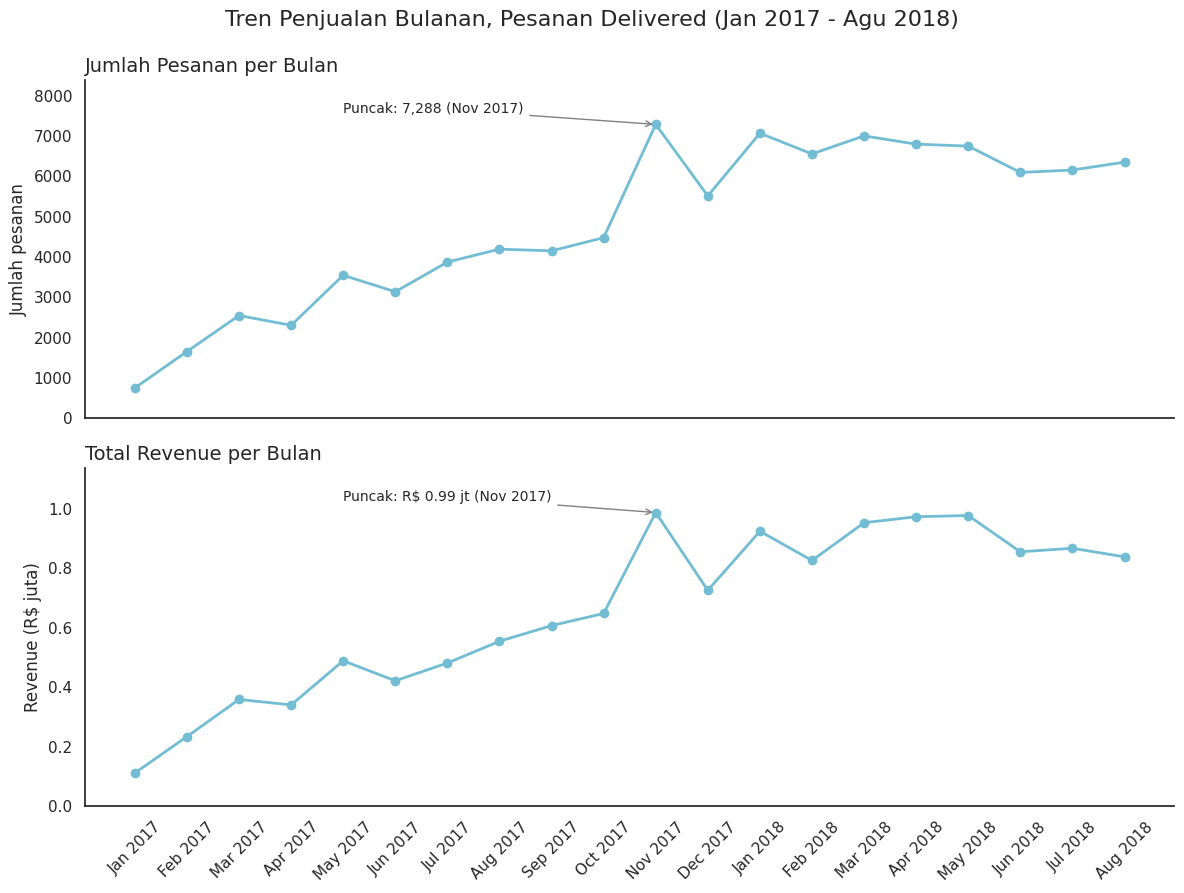

In [69]:
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(12, 9), sharex=True)
x = monthly_df["month_label"]

# Jumlah pesanan
ax[0].plot(x, monthly_df["order_count"], marker="o", linewidth=2, color=HIGHLIGHT)
ax[0].set_title("Jumlah Pesanan per Bulan", loc="left", fontsize=14)
ax[0].set_ylabel("Jumlah pesanan")
ax[0].set_ylim(0, monthly_df["order_count"].max() * 1.15)
i = monthly_df["order_count"].idxmax()
ax[0].annotate(f"Puncak: {monthly_df.loc[i, 'order_count']:,} ({monthly_df.loc[i, 'month_label']})",
               xy=(i, monthly_df.loc[i, "order_count"]), xytext=(i - 6, monthly_df.loc[i, "order_count"] * 1.04),
               arrowprops=dict(arrowstyle="->", color="grey"), fontsize=10)

# Revenue
ax[1].plot(x, monthly_df["revenue"] / 1e6, marker="o", linewidth=2, color=HIGHLIGHT)
ax[1].set_title("Total Revenue per Bulan", loc="left", fontsize=14)
ax[1].set_ylabel("Revenue (R$ juta)")
ax[1].set_ylim(0, monthly_df["revenue"].max() / 1e6 * 1.15)
j = monthly_df["revenue"].idxmax()
ax[1].annotate(f"Puncak: R$ {monthly_df.loc[j, 'revenue'] / 1e6:.2f} jt ({monthly_df.loc[j, 'month_label']})",
               xy=(j, monthly_df.loc[j, "revenue"] / 1e6), xytext=(j - 6, monthly_df.loc[j, "revenue"] / 1e6 * 1.04),
               arrowprops=dict(arrowstyle="->", color="grey"), fontsize=10)
ax[1].tick_params(axis="x", rotation=45)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.suptitle("Tren Penjualan Bulanan, Pesanan Delivered (Jan 2017 - Agu 2018)", fontsize=16, y=0.99)
plt.tight_layout()
plt.show()

**Penjelasan (Pertanyaan 1):**
- Jumlah pesanan dan revenue naik tajam sepanjang 2017 (dari 750 pesanan / R\$ 112 ribu pada Januari 2017) dan mencapai puncak pada **November 2017** (7.288 pesanan; R\$ 987,6 ribu). Puncak ini ditandai hari tertinggi 24 November 2017 (1.147 pesanan; bertepatan dengan Black Friday) dan hari-hari sesudahnya yang tetap tinggi (rata-rata 368 pesanan per hari pada 25-30 November). Kaitannya dengan Black Friday tidak dapat dipastikan dari data.
- Setelah puncak, Desember 2017 turun 26,5% (penurunan MoM terbesar), lalu 2018 bergerak mendatar di kisaran 6.100-7.100 pesanan per bulan. Angka 2018 yang jauh lebih tinggi (Jan-Agu 2018 naik 141% dibanding Jan-Agu 2017) mencerminkan level penjualan yang sudah tinggi sejak akhir 2017, bukan tren naik berkelanjutan sepanjang 2018.
- Pola revenue hampir identik dengan pola pesanan, sehingga pergerakan revenue terutama digerakkan oleh volume pesanan, bukan perubahan nilai per pesanan (revenue per pesanan relatif stabil, mis. R\$ 149 pada Jan 2017, R\$ 136 pada Nov 2017, R\$ 132 pada Agu 2018).

### Pertanyaan 2: Kategori produk apa yang menyumbang revenue terbesar dan terkecil?

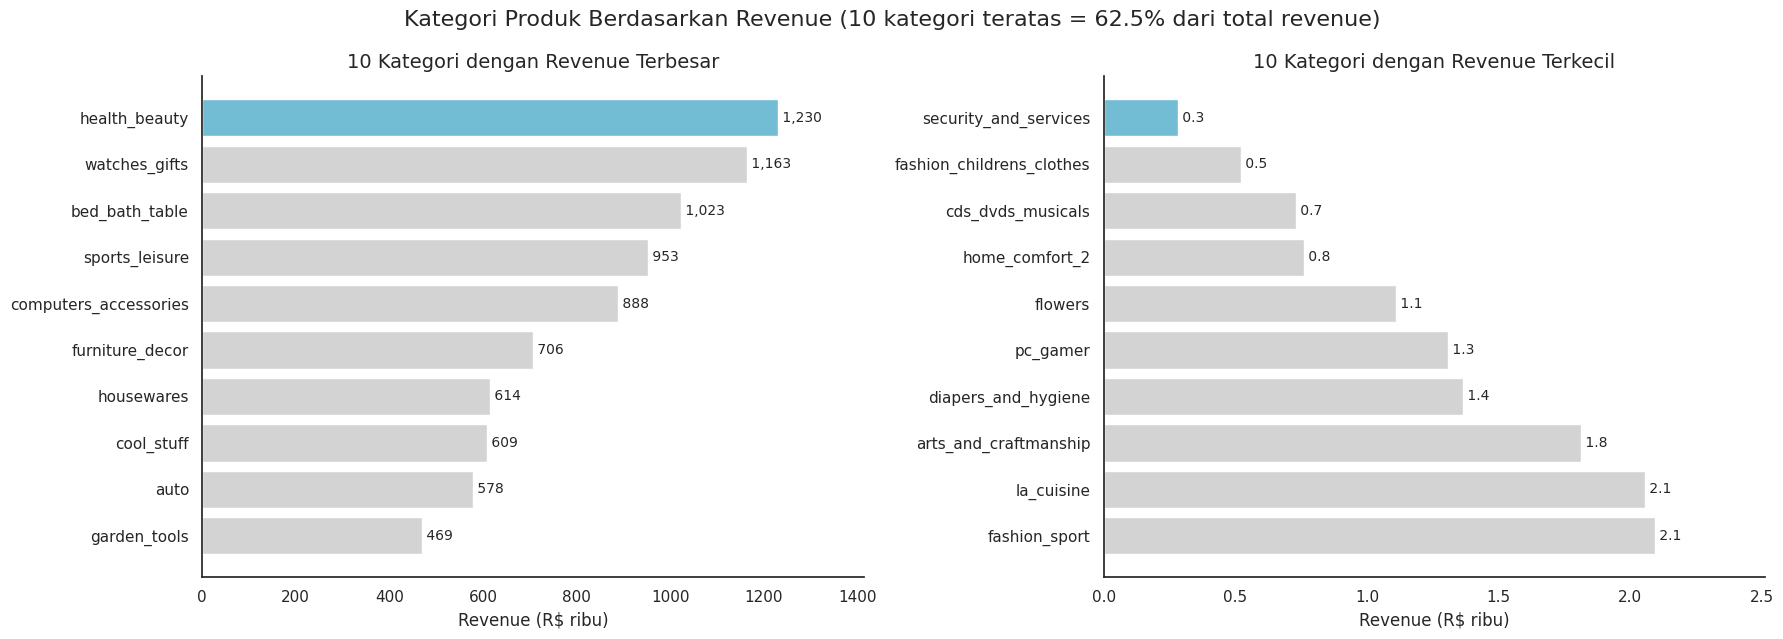

In [70]:
top10 = category_df.head(10).iloc[::-1]
bottom10 = category_df.tail(10).iloc[::-1]

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6.5))

# 10 teratas (sorot yang tertinggi)
colors_top = [GREY] * 9 + [HIGHLIGHT]
ax[0].barh(top10["product_category"], top10["revenue"] / 1e3, color=colors_top)
ax[0].set_title("10 Kategori dengan Revenue Terbesar", loc="center", fontsize=14)
ax[0].set_xlabel("Revenue (R$ ribu)")
for k, v in enumerate(top10["revenue"] / 1e3):
    ax[0].text(v, k, f" {v:,.0f}", va="center", fontsize=10)
ax[0].set_xlim(0, top10["revenue"].max() / 1e3 * 1.15)

# 10 terbawah (sorot yang terendah, sesuai pesan grafik)
colors_bottom = [GREY] * 9 + [HIGHLIGHT]
bottom_sorted = category_df.tail(10).sort_values("revenue", ascending=False)
ax[1].barh(bottom_sorted["product_category"], bottom_sorted["revenue"] / 1e3, color=colors_bottom)
ax[1].set_title("10 Kategori dengan Revenue Terkecil", loc="center", fontsize=14)
ax[1].set_xlabel("Revenue (R$ ribu)")
for k, v in enumerate(bottom_sorted["revenue"] / 1e3):
    ax[1].text(v, k, f" {v:,.1f}", va="center", fontsize=10)
ax[1].set_xlim(0, bottom_sorted["revenue"].max() / 1e3 * 1.2)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.suptitle(f"Kategori Produk Berdasarkan Revenue (10 kategori teratas = {top10_share:.1f}% dari total revenue)", fontsize=16)
plt.tight_layout()
plt.show()

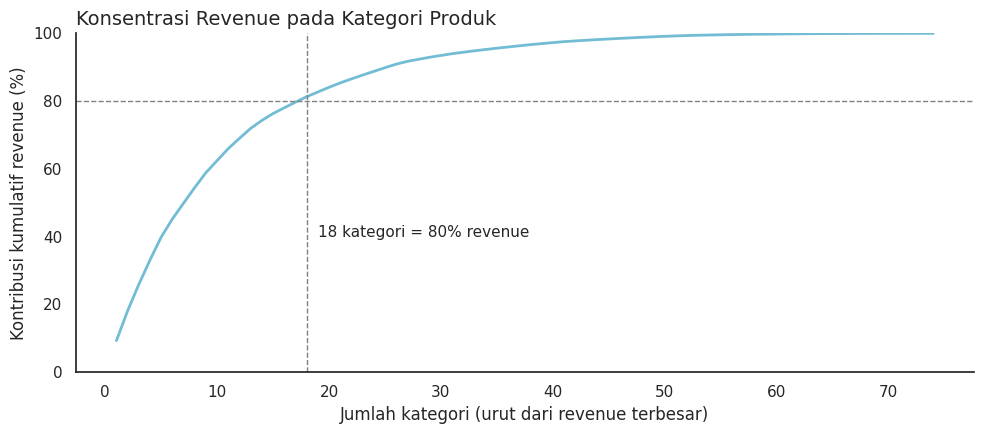

In [71]:
# Kurva Pareto: berapa kategori yang menyumbang 80% revenue?
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(range(1, len(category_df) + 1), category_df["cum_share_pct"], color=HIGHLIGHT, linewidth=2)
ax.axhline(80, color="grey", linestyle="--", linewidth=1)
ax.axvline(n80, color="grey", linestyle="--", linewidth=1)
ax.text(n80 + 1, 40, f"{n80} kategori = 80% revenue", fontsize=11)
ax.set_ylim(0, 100)
ax.set_xlabel("Jumlah kategori (urut dari revenue terbesar)")
ax.set_ylabel("Kontribusi kumulatif revenue (%)")
ax.set_title("Konsentrasi Revenue pada Kategori Produk", loc="left", fontsize=14)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Penjelasan (Pertanyaan 2):**
- Revenue sangat terkonsentrasi: 10 kategori teratas menyumbang **62,5%** revenue dan 18 kategori sudah mencapai 80%. Kategori terbesar adalah **health_beauty (R\$ 1,23 juta)**, disusul watches_gifts dan bed_bath_table.
- Sebaliknya, 10 kategori terbawah hanya menyumbang kurang dari R\$ 2.100 per kategori (terkecil `security_and_services` R\$ 283); kontribusinya hampir nol terhadap total revenue.
- `watches_gifts` menunjukkan nilai per item tinggi (sekitar R\$ 199) sementara `bed_bath_table` bervolume tinggi dengan nilai per item rendah (sekitar R\$ 94), sehingga strategi promosinya perlu dibedakan.

### Pertanyaan 3: Seberapa besar keterlambatan pengiriman per state, dan bagaimana dampaknya pada review score?

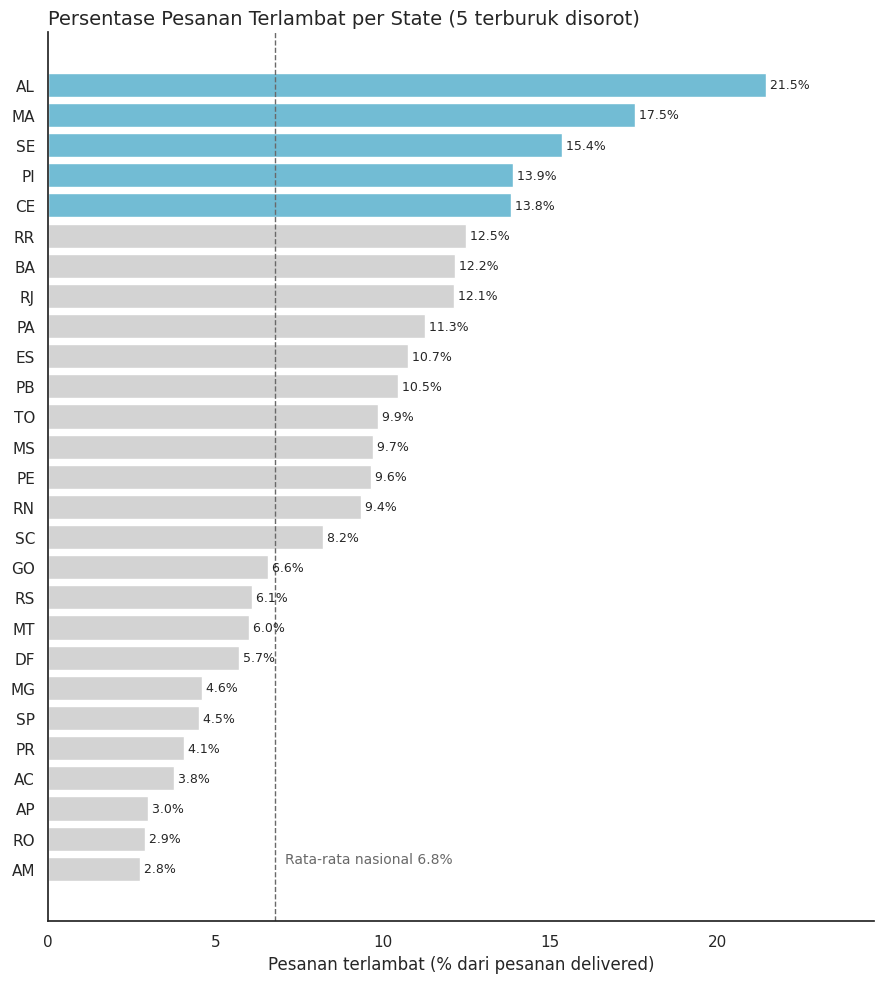

In [72]:
plot_state = state_df.sort_values("late_pct", ascending=True)
colors_state = [GREY] * (len(plot_state) - 5) + [HIGHLIGHT] * 5      # sorot 5 state terburuk

fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(plot_state["customer_state"], plot_state["late_pct"], color=colors_state)
ax.axvline(overall_late, color="dimgray", linestyle="--", linewidth=1)
ax.text(overall_late + 0.3, 0.2, f"Rata-rata nasional {overall_late:.1f}%", fontsize=10, color="dimgray")
for k, (v, n) in enumerate(zip(plot_state["late_pct"], plot_state["order_count"])):
    ax.text(v, k, f" {v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Pesanan terlambat (% dari pesanan delivered)")
ax.set_title("Persentase Pesanan Terlambat per State (5 terburuk disorot)", loc="left", fontsize=14)
ax.set_xlim(0, plot_state["late_pct"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

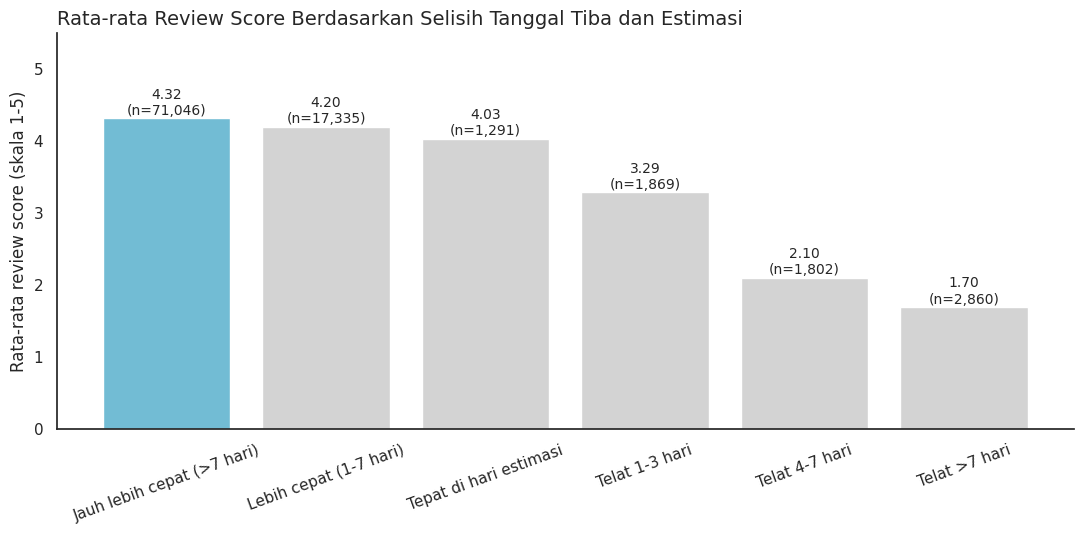

In [73]:
fig, ax = plt.subplots(figsize=(11, 5.5))
highest = delay_df["avg_review"].idxmax()
colors_delay = [GREY] * len(delay_df)
colors_delay[highest] = HIGHLIGHT
bars = ax.bar(delay_df["delay_group"].astype(str), delay_df["avg_review"], color=colors_delay)
for b, v, n in zip(bars, delay_df["avg_review"], delay_df["order_count"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.05, f"{v:.2f}\n(n={n:,})", ha="center", fontsize=10)
ax.set_ylim(0, 5.5)
ax.set_ylabel("Rata-rata review score (skala 1-5)")
ax.set_title("Rata-rata Review Score Berdasarkan Selisih Tanggal Tiba dan Estimasi", loc="left", fontsize=14)
ax.tick_params(axis="x", rotation=20)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Penjelasan (Pertanyaan 3):**
- Lima state dengan persentase keterlambatan tertinggi seluruhnya di wilayah Nordeste: AL (21,5%), MA (17,5%), SE (15,4%), PI (13,9%), dan CE (13,8%); semuanya jauh di atas rata-rata nasional 6,8%. State besar dengan tingkat tinggi adalah **RJ (12,1%)** dan BA (12,2%).
- Dari sisi volume, SP dan RJ bersama-sama menyumbang sekitar 51% dari seluruh pesanan terlambat, sehingga perbaikan di RJ memberi dampak absolut jauh lebih besar daripada di AL (yang hanya 396 pesanan).
- Keterlambatan berkaitan erat dengan kepuasan: review turun dari 4,29 (tepat waktu) menjadi 3,29 untuk telat 1-3 hari, 2,10 untuk telat 4-7 hari, dan 1,70 untuk telat lebih dari 7 hari. Penurunan terbesar sudah terjadi sejak hari pertama terlambat.

**Insight:**
- Pertanyaan 1-3 dijawab dengan visualisasi yang disorot satu warna (HIGHLIGHT) untuk pesan utama dan abu-abu untuk pembanding; sumbu bar dimulai dari nol dan setiap grafik berlabel nilai/satuan.
- Revenue didorong oleh volume pesanan, dengan puncak bulanan November 2017 (hari tertinggi 24 November); revenue terkonsentrasi pada sedikit kategori; dan keterlambatan pengiriman terbukti berkaitan dengan review rendah, terutama di Nordeste serta RJ.

## Analisis Lanjutan (Opsional)

Tiga teknik analisis lanjutan diterapkan tanpa algoritma machine learning:

1. **RFM Analysis** - mengelompokkan pelanggan berdasarkan perilaku pembelian (*Recency*: hari sejak pembelian terakhir, *Frequency*: jumlah pesanan, *Monetary*: total belanja). Tujuannya mengidentifikasi pelanggan bernilai tinggi dan yang berisiko hilang, sehingga strategi retensi bisa dibedakan per segmen (menjawab **Pertanyaan 4**).
2. **Geospatial Analysis** - memetakan distribusi pelanggan, revenue, dan tingkat keterlambatan berdasarkan lokasi geografis untuk melihat pola antarwilayah (melengkapi Pertanyaan 3).
3. **Clustering manual (Manual Grouping dan Binning)** - pengelompokan state ke dalam 5 wilayah geografis Brasil dan pengelompokan nilai pesanan ke dalam tier harga berdasarkan aturan bisnis, bukan algoritma.

### 1. RFM Analysis (Pertanyaan 4)

Unit pelanggan adalah `customer_unique_id` (bukan `customer_id`, karena `customer_id` berubah pada setiap pesanan). Tanggal acuan (snapshot) adalah sehari setelah pembelian terakhir pada data. Skor R dan M dibagi menjadi 5 kelompok sama besar (kuintil; 5 = terbaik). Karena sebagian besar pelanggan hanya membeli sekali, frekuensi tidak dapat dibagi kuintil dan dikelompokkan secara manual: **1 pesanan** vs **2+ pesanan**.

Aturan segmen:

| Segmen | Aturan |
|---|---|
| Champions | Frequency >= 2 dan R >= 4 (pembeli ulang dan masih baru) |
| Loyal Customers | Frequency >= 2 dan R < 4 |
| New Big Spenders | Frequency = 1, R >= 4, M >= 4 |
| New Customers | Frequency = 1, R >= 4, M < 4 |
| Big Spenders at Risk | Frequency = 1, R < 4, M >= 4 |
| Hibernating | Frequency = 1, R < 4, M < 4 |

In [74]:
snapshot_date = all_df["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)

rfm_df = (all_df.groupby("customer_unique_id", as_index=False)
                .agg(last_order=("order_purchase_timestamp", "max"),
                     frequency=("order_id", "nunique"),
                     monetary=("price", "sum")))
rfm_df["recency"] = (snapshot_date - rfm_df["last_order"].dt.normalize()).dt.days

# Skor kuintil (rank "first" dipakai agar batas kelompok unik)
rfm_df["r_score"] = pd.qcut(rfm_df["recency"].rank(method="first", ascending=False), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

repeat = rfm_df["frequency"] >= 2
recent = rfm_df["r_score"] >= 4
big = rfm_df["m_score"] >= 4
rfm_df["segment"] = np.select(
    [repeat & recent, repeat & ~recent, ~repeat & recent & big, ~repeat & recent & ~big, ~repeat & ~recent & big],
    ["Champions", "Loyal Customers", "New Big Spenders", "New Customers", "Big Spenders at Risk"],
    default="Hibernating")

print("Tanggal acuan:", snapshot_date.date())
print(f"Pelanggan yang membeli ulang (2+ pesanan): {repeat.mean():.1%}  ({repeat.sum():,} dari {len(rfm_df):,})")
rfm_df.head()

Tanggal acuan: 2018-08-30
Pelanggan yang membeli ulang (2+ pesanan): 3.0%  (2,789 dari 93,096)


,customer_unique_id,last_order,frequency,monetary,recency,r_score,m_score,segment
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,129.90,112,4,4,New Big Spenders
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,18.90,115,4,1,New Customers
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,69.00,538,1,2,Hibernating
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,25.99,322,2,1,Hibernating
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,180.00,289,2,5,Big Spenders at Risk


In [75]:
segment_df = (rfm_df.groupby("segment")
                    .agg(customers=("customer_unique_id", "count"), revenue=("monetary", "sum"),
                         avg_recency=("recency", "mean"), avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean"))
                    .reset_index())
segment_df["customer_share_pct"] = segment_df["customers"] / segment_df["customers"].sum() * 100
segment_df["revenue_share_pct"] = segment_df["revenue"] / segment_df["revenue"].sum() * 100
segment_df = segment_df.sort_values("revenue_share_pct", ascending=False).reset_index(drop=True)
segment_df.round(2)

,segment,customers,revenue,avg_recency,avg_frequency,avg_monetary,customer_share_pct,revenue_share_pct
0,Big Spenders at Risk,20675,5530288.34,334.48,1.00,267.49,22.21,41.96
1,New Big Spenders,14438,3855966.92,91.95,1.00,267.07,15.51,29.26
2,Hibernating,33589,1868821.58,336.04,1.00,55.64,36.08,14.18
3,New Customers,21605,1199346.07,89.92,1.00,55.51,23.21,9.10
4,Loyal Customers,1594,401478.30,318.54,2.08,251.87,1.71,3.05
5,Champions,1195,323876.74,88.82,2.15,271.03,1.28,2.46


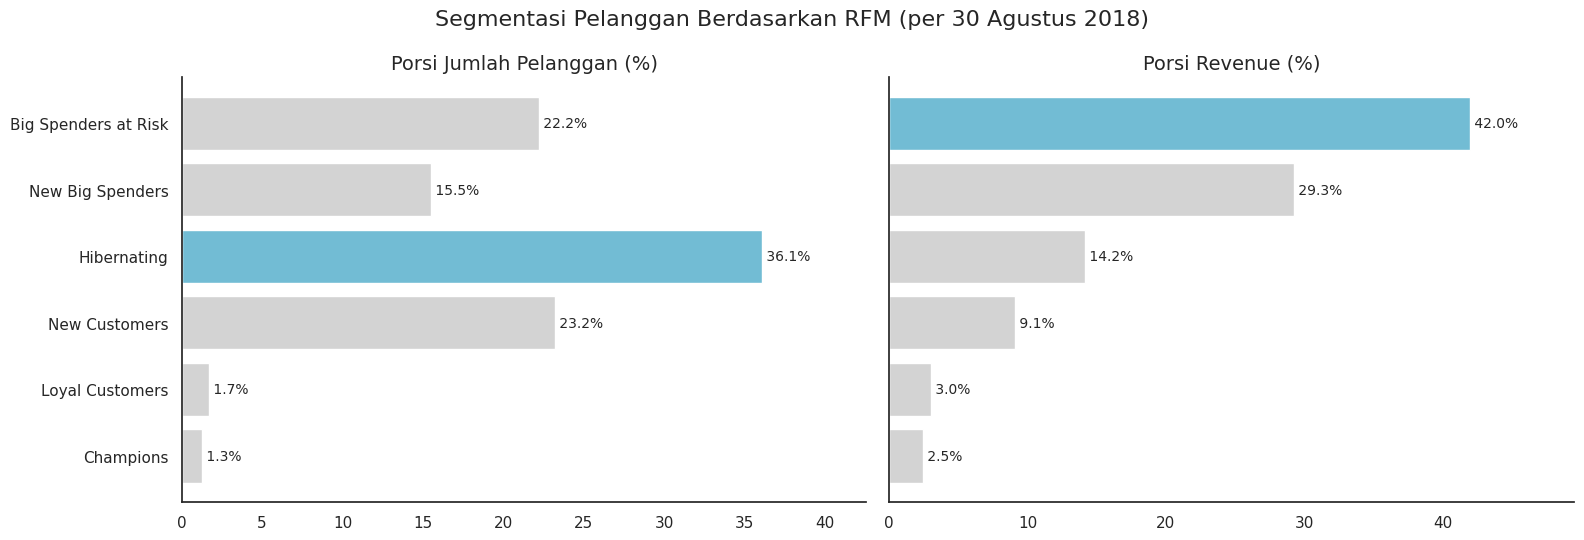

In [76]:
seg = segment_df.sort_values("revenue_share_pct")

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 5.5), sharey=True)
c_cust = [HIGHLIGHT if i == seg["customer_share_pct"].idxmax() else GREY for i in seg.index]
c_rev = [HIGHLIGHT if i == seg["revenue_share_pct"].idxmax() else GREY for i in seg.index]

ax[0].barh(seg["segment"], seg["customer_share_pct"], color=c_cust)
ax[0].set_title("Porsi Jumlah Pelanggan (%)", fontsize=14)
for k, v in enumerate(seg["customer_share_pct"]):
    ax[0].text(v, k, f" {v:.1f}%", va="center", fontsize=10)
ax[0].set_xlim(0, seg["customer_share_pct"].max() * 1.18)

ax[1].barh(seg["segment"], seg["revenue_share_pct"], color=c_rev)
ax[1].set_title("Porsi Revenue (%)", fontsize=14)
for k, v in enumerate(seg["revenue_share_pct"]):
    ax[1].text(v, k, f" {v:.1f}%", va="center", fontsize=10)
ax[1].set_xlim(0, seg["revenue_share_pct"].max() * 1.18)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.suptitle("Segmentasi Pelanggan Berdasarkan RFM (per 30 Agustus 2018)", fontsize=16)
plt.tight_layout()
plt.show()

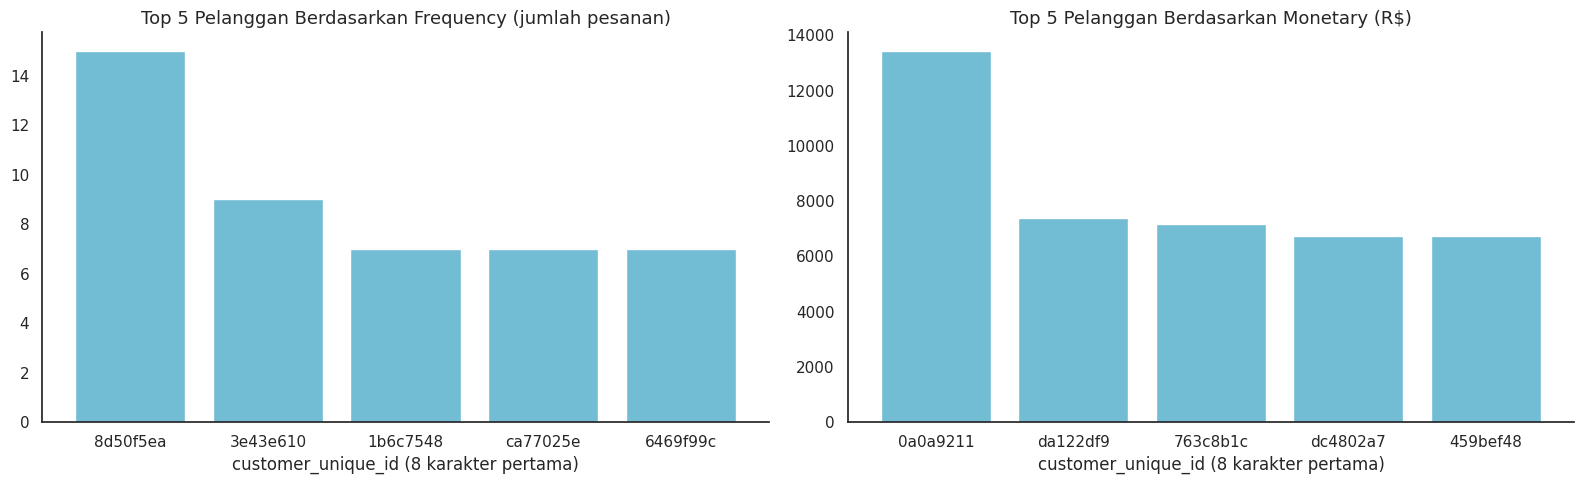

In [77]:
# Pelanggan terbaik berdasarkan frekuensi dan monetary (top 5), serupa contoh pada materi
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))
tf = rfm_df.sort_values(["frequency", "monetary"], ascending=False).head(5)
tm = rfm_df.sort_values("monetary", ascending=False).head(5)

ax[0].bar(tf["customer_unique_id"].str[:8], tf["frequency"], color=HIGHLIGHT)
ax[0].set_title("Top 5 Pelanggan Berdasarkan Frequency (jumlah pesanan)", fontsize=13)
ax[1].bar(tm["customer_unique_id"].str[:8], tm["monetary"], color=HIGHLIGHT)
ax[1].set_title("Top 5 Pelanggan Berdasarkan Monetary (R$)", fontsize=13)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
    a.set_xlabel("customer_unique_id (8 karakter pertama)")
plt.tight_layout()
plt.show()

**Insight:**
- Dari 93.096 pelanggan, **hanya 3,0% (2.789 pelanggan) yang membeli lebih dari satu kali**; 97% adalah pembeli sekali. Retensi adalah titik lemah utama.
- **Big Spenders at Risk**: 22,2% pelanggan (20.675 orang) menyumbang **42,0% revenue (R\$ 5,53 juta)**, rata-rata belanja R\$ 267, tetapi terakhir membeli sekitar 334 hari lalu.
- **New Big Spenders**: 15,5% pelanggan menyumbang 29,3% revenue. Kedua segmen *big spender* gabungan (37,7% pelanggan) menyumbang **71,2% revenue**.
- **Hibernating**: segmen terbesar (36,1% pelanggan) tetapi hanya 14,2% revenue (rata-rata belanja R\$ 56). **Champions + Loyal** hanya 3,0% pelanggan dan 5,5% revenue.

### 2. Geospatial Analysis

Titik koordinat pelanggan berasal dari rata-rata koordinat per kode pos (`geo_zip`). Peta kiri menunjukkan lokasi pelanggan (abu-abu) dan revenue per state (ukuran lingkaran). Peta kanan menunjukkan jumlah pesanan (ukuran) dan persentase keterlambatan (warna) per state. Peta interaktif dengan folium ada di bawahnya.

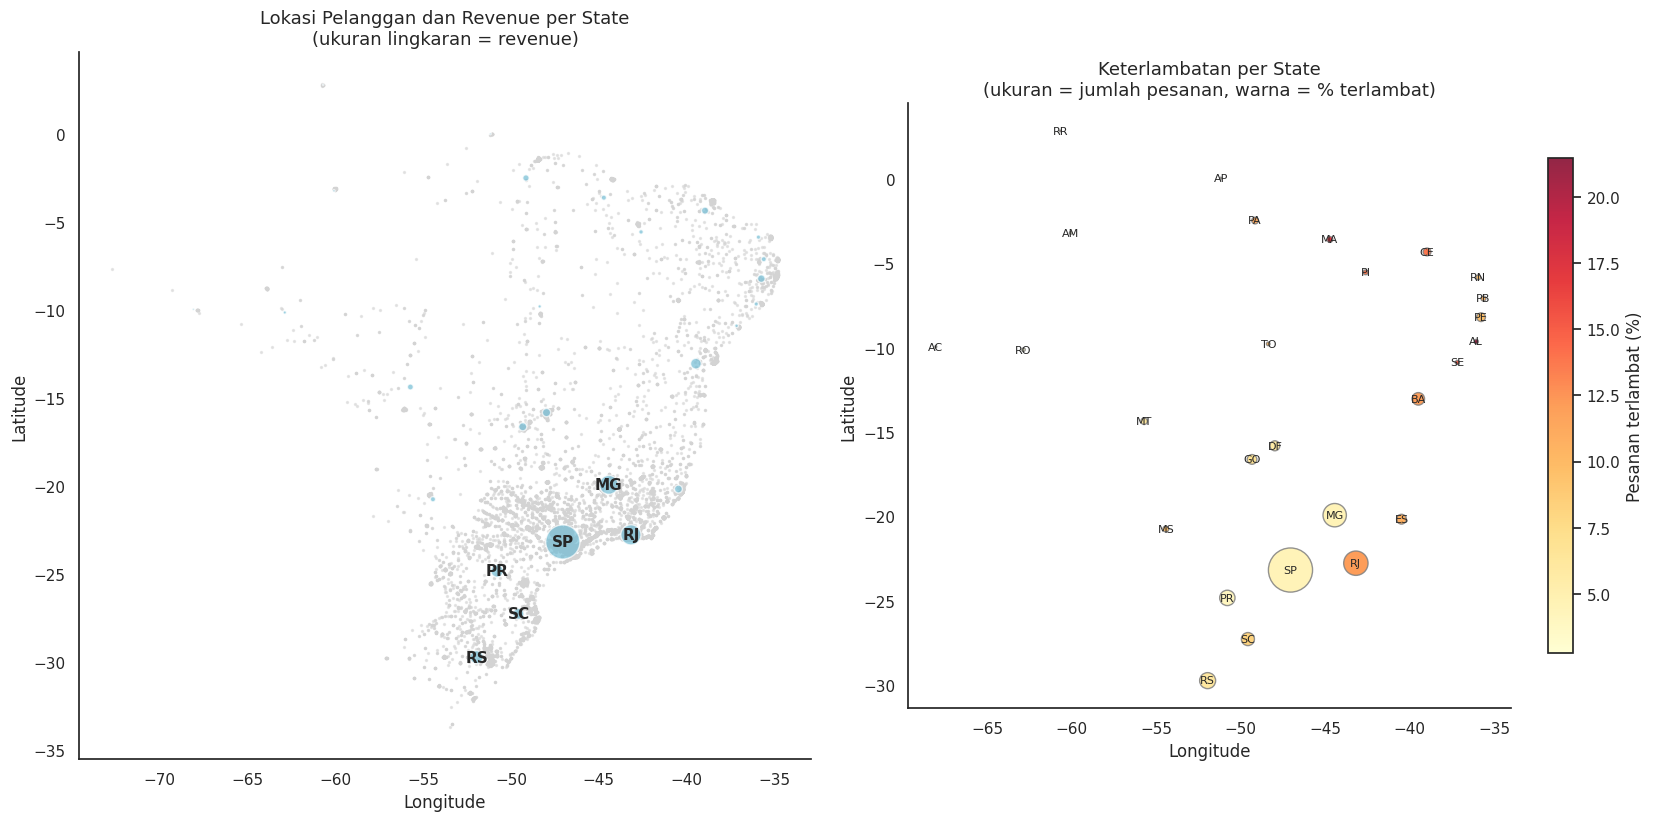

In [78]:
geo_state = (all_df.groupby("customer_state")
                   .agg(customers=("customer_unique_id", "nunique"), orders=("order_id", "nunique"),
                        revenue=("price", "sum"), lat=("customer_lat", "mean"), lng=("customer_lng", "mean"))
                   .reset_index()
                   .merge(state_df[["customer_state", "late_pct", "avg_review"]], on="customer_state"))
geo_state["region"] = geo_state["customer_state"].map(REGION_MAP)

# Sampel titik pelanggan agar peta tidak terlalu padat
pts = all_df.drop_duplicates("customer_unique_id").dropna(subset=["customer_lat"]).sample(25000, random_state=42)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(17, 8))

ax[0].scatter(pts["customer_lng"], pts["customer_lat"], s=2, color=GREY, alpha=0.5)
ax[0].scatter(geo_state["lng"], geo_state["lat"], s=geo_state["revenue"] / 1e6 * 120, color=HIGHLIGHT, alpha=0.7, edgecolor="white")
for _, r in geo_state.nlargest(6, "revenue").iterrows():
    ax[0].text(r["lng"], r["lat"], r["customer_state"], fontsize=11, ha="center", va="center", fontweight="bold")
ax[0].set_title("Lokasi Pelanggan dan Revenue per State\n(ukuran lingkaran = revenue)", fontsize=13)

sc = ax[1].scatter(geo_state["lng"], geo_state["lat"], s=geo_state["orders"] / 40, c=geo_state["late_pct"],
                   cmap="YlOrRd", alpha=0.85, edgecolor="grey")
for _, r in geo_state.iterrows():
    ax[1].text(r["lng"], r["lat"], r["customer_state"], fontsize=8, ha="center", va="center")
cb = plt.colorbar(sc, ax=ax[1], shrink=0.7)
cb.set_label("Pesanan terlambat (%)")
ax[1].set_title("Keterlambatan per State\n(ukuran = jumlah pesanan, warna = % terlambat)", fontsize=13)

for a in ax:
    a.set_xlabel("Longitude")
    a.set_ylabel("Latitude")
    a.set_aspect("equal")
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [79]:
# Peta interaktif (folium)
try:
    import folium
    m = folium.Map(location=[-14.2, -51.9], zoom_start=4, tiles="cartodbpositron")
    for _, r in geo_state.iterrows():
        folium.CircleMarker(
            location=[r["lat"], r["lng"]],
            radius=4 + (r["revenue"] / geo_state["revenue"].max()) * 26,
            color="#2b7a99", fill=True, fill_color="#72BCD4", fill_opacity=0.7,
            tooltip=(f"{r['customer_state']} | revenue R$ {r['revenue']:,.0f} | {r['orders']:,} pesanan | "
                     f"terlambat {r['late_pct']:.1f}% | review {r['avg_review']:.2f}"),
        ).add_to(m)
    display(m)
except ImportError:
    print("folium belum terpasang: pip install folium")

In [80]:
geo_state.sort_values("revenue", ascending=False)[["customer_state", "region", "customers", "orders", "revenue", "late_pct", "avg_review"]].head(10).round(2)

,customer_state,region,customers,orders,revenue,late_pct,avg_review
25,SP,Sudeste,39058,40399,5054516.95,4.50,4.25
18,RJ,Sudeste,11879,12310,1751433.85,12.14,3.97
10,MG,Sudeste,10969,11319,1548206.88,4.59,4.19
22,RS,Sul,5150,5327,726194.92,6.10,4.19
17,PR,Sul,4750,4903,664048.00,4.06,4.24
23,SC,Sul,3441,3537,504774.07,8.23,4.13
4,BA,Nordeste,3155,3253,493339.26,12.17,3.93
6,DF,Centro-Oeste,2013,2074,295454.64,5.69,4.13
8,GO,Centro-Oeste,1889,1950,281932.21,6.56,4.10
7,ES,Sudeste,1925,1992,267783.66,10.74,4.08


**Insight:**
- Aktivitas sangat terpusat di Sudeste: **68,6% pesanan dan 65,4% revenue**; SP sendiri R\$ 5,05 juta (38,4% revenue). Titik pelanggan padat di pesisir timur/tenggara Brasil.
- Nordeste memiliki performa pengiriman terburuk di antara wilayah besar: terlambat 12,8% (Sudeste 6,1%), rata-rata pengiriman 20,0 hari (Sudeste 10,7 hari), review 3,97 (Sudeste 4,18). Norte punya waktu pengiriman terlama (22,6 hari) tetapi tingkat telatnya 8,6%.
- **RJ adalah anomali di Sudeste**: tingkat terlambat 12,1%, jauh di atas SP (4,5%) dan MG (4,6%), padahal volumenya besar (12.310 pesanan).

### 3. Clustering Manual (Manual Grouping dan Binning)

**Manual grouping:** 27 state dikelompokkan menjadi 5 wilayah geografis resmi Brasil (Norte, Nordeste, Centro-Oeste, Sudeste, Sul) agar pola regional lebih mudah dibaca.

**Binning:** nilai pesanan dibagi menjadi 4 tier berdasarkan aturan bisnis (< R\$ 50, R\$ 50-150, R\$ 150-500, > R\$ 500).

In [81]:
region_df = (order_df.assign(order_value=all_df.groupby("order_id")["price"].sum().reindex(order_df["order_id"]).values)
                     .groupby("region")
                     .agg(orders=("order_id", "count"), revenue=("order_value", "sum"),
                          late_pct=("is_late", lambda s: s.mean() * 100),
                          avg_delivery_days=("delivery_days", "mean"), avg_review=("review_score", "mean"))
                     .reset_index())
region_df["order_share_pct"] = region_df["orders"] / region_df["orders"].sum() * 100
region_df["revenue_share_pct"] = region_df["revenue"] / region_df["revenue"].sum() * 100
region_df = region_df.sort_values("orders", ascending=False).reset_index(drop=True)
region_df.round(2)

,region,orders,revenue,late_pct,avg_delivery_days,avg_review,order_share_pct,revenue_share_pct
0,Sudeste,66020,8621941.34,6.13,10.73,4.18,68.63,65.42
1,Sul,13767,1895016.99,5.92,14.02,4.19,14.31,14.38
2,Nordeste,9015,1491911.33,12.76,19.99,3.97,9.37,11.32
3,Centro-Oeste,5610,844960.64,6.54,15.01,4.13,5.83,6.41
4,Norte,1791,325947.65,8.60,22.59,4.03,1.86,2.47


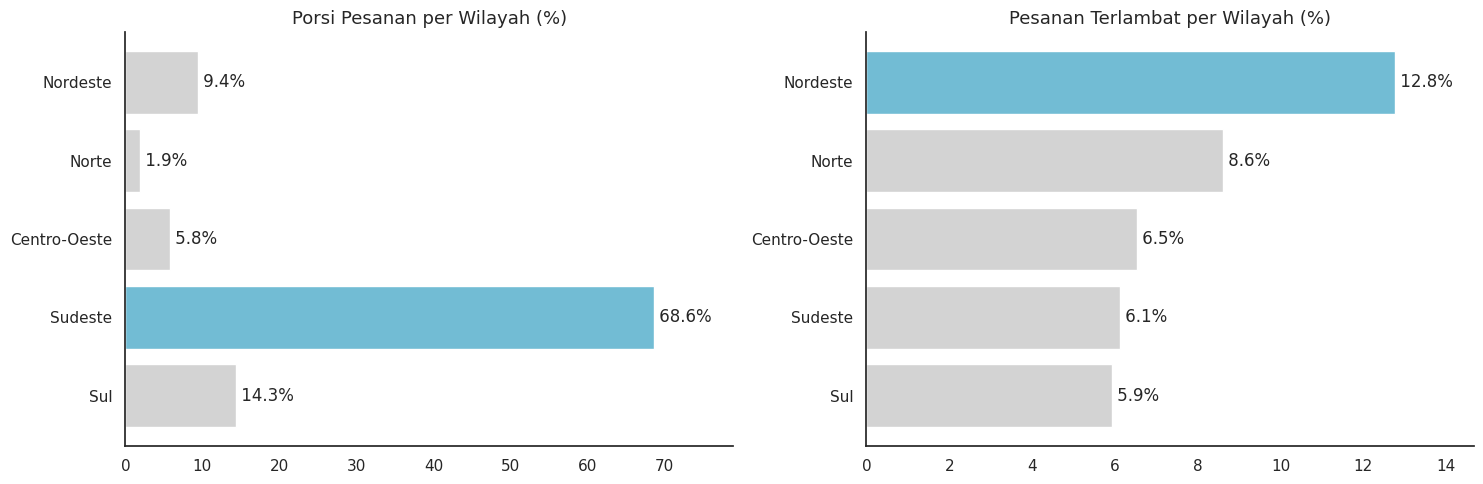

In [82]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
reg = region_df.sort_values("late_pct")
top_reg = reg["late_pct"].idxmax()
ax[0].barh(reg["region"], reg["order_share_pct"], color=[HIGHLIGHT if i == reg["order_share_pct"].idxmax() else GREY for i in reg.index])
ax[0].set_title("Porsi Pesanan per Wilayah (%)", fontsize=13)
for k, v in enumerate(reg["order_share_pct"]):
    ax[0].text(v, k, f" {v:.1f}%", va="center")
ax[0].set_xlim(0, reg["order_share_pct"].max() * 1.15)

ax[1].barh(reg["region"], reg["late_pct"], color=[HIGHLIGHT if i == top_reg else GREY for i in reg.index])
ax[1].set_title("Pesanan Terlambat per Wilayah (%)", fontsize=13)
for k, v in enumerate(reg["late_pct"]):
    ax[1].text(v, k, f" {v:.1f}%", va="center")
ax[1].set_xlim(0, reg["late_pct"].max() * 1.15)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [83]:
order_value = all_df.groupby("order_id")["price"].sum().rename("order_value").reset_index()
order_value["value_tier"] = pd.cut(order_value["order_value"], bins=[0, 50, 150, 500, np.inf],
                                   labels=["< R$ 50", "R$ 50-150", "R$ 150-500", "> R$ 500"])
tier_df = (order_value.groupby("value_tier", observed=True)
                      .agg(orders=("order_id", "count"), revenue=("order_value", "sum")).reset_index())
tier_df["order_share_pct"] = tier_df["orders"] / tier_df["orders"].sum() * 100
tier_df["revenue_share_pct"] = tier_df["revenue"] / tier_df["revenue"].sum() * 100
tier_df.round(2)

,value_tier,orders,revenue,order_share_pct,revenue_share_pct
0,< R$ 50,28962,926449.85,30.11,7.03
1,R$ 50-150,43991,4167801.24,45.73,31.62
2,R$ 150-500,19787,4852912.16,20.57,36.82
3,> R$ 500,3463,3232614.70,3.60,24.53


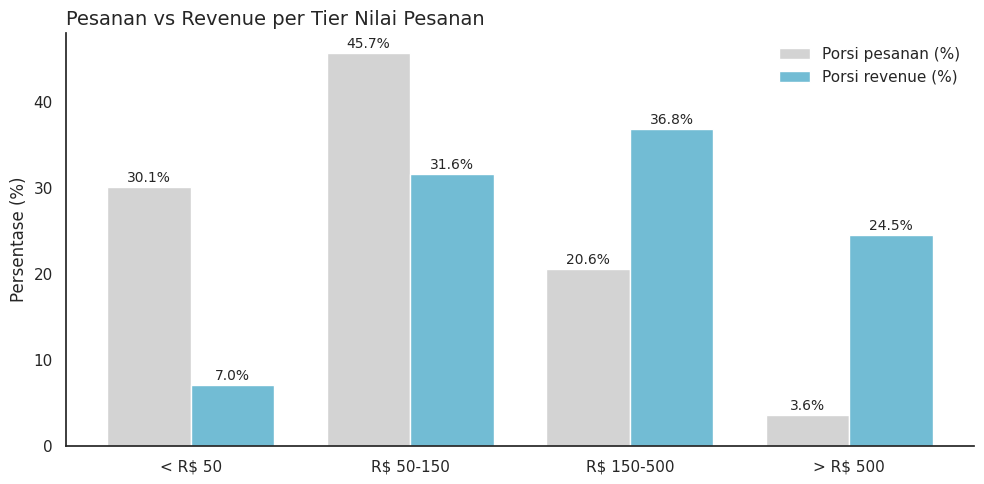

In [84]:
fig, ax = plt.subplots(figsize=(10, 5))
w = 0.38
xx = np.arange(len(tier_df))
ax.bar(xx - w / 2, tier_df["order_share_pct"], width=w, color=GREY, label="Porsi pesanan (%)")
ax.bar(xx + w / 2, tier_df["revenue_share_pct"], width=w, color=HIGHLIGHT, label="Porsi revenue (%)")
for k, (a_, b_) in enumerate(zip(tier_df["order_share_pct"], tier_df["revenue_share_pct"])):
    ax.text(k - w / 2, a_ + 0.6, f"{a_:.1f}%", ha="center", fontsize=10)
    ax.text(k + w / 2, b_ + 0.6, f"{b_:.1f}%", ha="center", fontsize=10)
ax.set_xticks(xx)
ax.set_xticklabels(tier_df["value_tier"])
ax.set_ylabel("Persentase (%)")
ax.set_title("Pesanan vs Revenue per Tier Nilai Pesanan", loc="left", fontsize=14)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Insight:**
- **Manual grouping wilayah:** Sudeste dan Sul menyumbang 82,9% pesanan, sedangkan Nordeste (9,4% pesanan) memiliki tingkat terlambat tertinggi (12,8%) dan review terendah (3,97).
- **Binning nilai pesanan:** pesanan di bawah R\$ 50 adalah 30,1% dari pesanan tetapi hanya 7,0% revenue, sedangkan pesanan di atas R\$ 500 hanya 3,6% pesanan namun menyumbang 24,5% revenue. Tier R\$ 150-500 menyumbang 36,8% revenue dari 20,6% pesanan. Pesanan bernilai tinggi (lebih dari R\$ 150) hanya 24,2% pesanan tetapi 61,4% revenue.

### Menyimpan Data untuk Dashboard

Data hasil pembersihan dan penggabungan disimpan sebagai `dashboard/main_data.csv` agar dashboard Streamlit tidak perlu memproses ulang dataset mentah yang besar (terutama `geolocation`, sekitar 60 MB).

In [85]:
export_cols = ["order_id", "customer_unique_id", "order_purchase_timestamp", "order_delivered_customer_date",
               "order_estimated_delivery_date", "customer_state", "customer_city", "region",
               "product_category", "price", "freight_value", "review_score", "delay_days", "is_late",
               "delivery_days", "customer_lat", "customer_lng"]
main_data = all_df[export_cols].copy()
main_data["delivery_days"] = main_data["delivery_days"].round(2)
main_data["customer_lat"] = main_data["customer_lat"].round(4)
main_data["customer_lng"] = main_data["customer_lng"].round(4)

os.makedirs("dashboard", exist_ok=True)
main_data.to_csv("dashboard/main_data.csv", index=False)
print("main_data.csv:", main_data.shape, "|", round(os.path.getsize("dashboard/main_data.csv") / 1e6, 1), "MB")

main_data.csv: (109872, 17) | 22.1 MB


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pesanan dan revenue tumbuh sangat tajam sepanjang 2017 dan mencapai puncak pada **November 2017 (7.288 pesanan; R\$ 987,6 ribu)** yang ditandai hari tertinggi 24 November 2017 (1.147 pesanan, bertepatan dengan Black Friday) dan hari-hari sesudahnya yang tetap tinggi. Penurunan MoM terbesar terjadi pada Desember 2017 (-26,5%). Sepanjang 2018 penjualan mendatar di 6.100-7.100 pesanan per bulan; revenue Jan-Agu 2018 naik 141% dibanding Jan-Agu 2017 karena basis yang lebih tinggi, namun belum ada pertumbuhan berkelanjutan di 2018.
- **Conclusion pertanyaan 2:** Revenue sangat terkonsentrasi: **10 kategori teratas = 62,5% revenue** dan 18 dari 74 kategori = 80%. Kategori terbesar adalah health_beauty (R\$ 1,23 juta), watches_gifts (R\$ 1,16 juta), dan bed_bath_table (R\$ 1,02 juta). Banyak kategori di ekor bawah menyumbang kurang dari R\$ 2.100 (terkecil security_and_services R\$ 283).
- **Conclusion pertanyaan 3:** **6,8% pesanan terlambat** secara nasional dan tertinggi di Nordeste (AL 21,5%, MA 17,5%, SE 15,4%, PI 13,9%, CE 13,8%); RJ (12,1%) dan SP menyumbang sekitar 51% dari seluruh pesanan terlambat karena volumenya. Review rata-rata turun dari 4,29 (tepat waktu) menjadi 2,27 (terlambat); telat 1-3 hari saja sudah turun ke 3,29 dan di atas 7 hari ke 1,70.
- **Conclusion pertanyaan 4:** Hanya **3,0% pelanggan yang membeli ulang**. Segmen *Big Spenders at Risk* (22,2% pelanggan) menyumbang **42,0% revenue** tetapi sudah lama tidak membeli (rata-rata 334 hari), dan dua segmen *big spender* gabungan menyumbang 71,2% revenue. Segmen Hibernating adalah yang terbesar (36,1% pelanggan) namun hanya 14,2% revenue.

**Rekomendasi Action Item:**
- **Perencanaan kampanye dan stok (Pertanyaan 1):** siapkan stok, kapasitas gudang, dan armada kurir sebelum Black Friday/akhir November, serta rencanakan kampanye penahan (mis. promo awal Desember) agar penurunan pasca-puncak (-26,5% pada Desember 2017) bisa dikurangi. Karena penjualan 2018 mendatar, tetapkan target pertumbuhan baru (akuisisi pelanggan/seller) di luar momen musiman.
- **Prioritas kategori (Pertanyaan 2):** fokuskan anggaran promosi dan penambahan seller pada 10 kategori teratas (62,5% revenue), terutama health_beauty dan watches_gifts. Untuk bed_bath_table yang volumenya tinggi dengan nilai per item rendah, gunakan bundling/cross-sell untuk menaikkan nilai pesanan. Tinjau kategori ekor bawah (revenue kurang dari R\$ 2.100) untuk dikonsolidasikan atau dievaluasi ulang.
- **Perbaikan logistik (Pertanyaan 3):** prioritaskan **RJ dan BA** (tingkat terlambat ±12% dengan volume besar) untuk audit kurir/rute, lalu AL, MA, SE, PI, CE (tingkat terlambat tertinggi) dengan kalibrasi estimasi dan mitra kurir regional. Kirim notifikasi proaktif bila pesanan diperkirakan terlambat lebih dari 1-3 hari, disertai kompensasi (voucher), karena review sudah jatuh sejak hari pertama terlambat. Tinjau juga estimasi yang terlalu longgar (73,9% pesanan tiba lebih dari 7 hari lebih awal).
- **Retensi pelanggan (Pertanyaan 4):** jalankan kampanye *win-back* personal untuk 20.675 pelanggan *Big Spenders at Risk* (42% revenue) dan program pembelian kedua (voucher/poin) untuk *New Big Spenders* dan *New Customers* dengan target menaikkan repeat rate dari 3,0%. Untuk segmen Hibernating bernilai rendah, gunakan saluran berbiaya murah (email/notifikasi) saja.